# Predicción del nivel máximo del río Magdalena

#Integrantes: Daniel Barros, Jhonny Rodriguez, Cristian Mendoza

Este es un trabajo experimental en el cual se pondrán a prueba diversos métodos de machine learning para determinar qué modelo según ciertos criterios es mejor para predecir el nivel máximo del río Magdalena.

El río Magdalena tiene una extensión de 1.540 kilómetros y atraviesa hasta 13 departamentos del territorio colombiano. Su nivel se mide con sensores. *Este dataset fue extraído desde la página oficial de Datos Abiertos Colombia y se puede obtener en el siguiente enlace: [Dataset utilizado](https://www.datos.gov.co/Ambiente-y-Desarrollo-Sostenible/Nivel-M-ximo-del-Rio/vfth-yucv/explore/query/SELECT%20%60fechaobservacion%60%2C%20%60valorobservado%60%0AWHERE%20caseless_one_of%28%60codigoestacion%60%2C%20"0025027020"%29/page/filter).*

Tenemos una **serie de tiempo**: un sensor registró el nivel del agua en
distintos horarios. Los datos están en `Nivel_Máximo_del_Rio_20261026.csv` y cubren desde el 4 de octubre de 2004 hasta el 24 de octubre de 2026, de la estación EL BANCO - AUT (código 25027020).

Según la [ficha del dataset](https://www.datos.gov.co/api/views/vfth-yucv.json), el nivel máximo es el punto más alto que alcanzó el agua durante una hora, en metros. Los datos son crudos, no validados por IDEAM por lo que pueden contener errores del sensor.

Este trabajo experimental es importante para la navegación ya que esta depende de que el río tenga un nivel alto de agua, además la comunicación a las poblaciones cercanas a las orillas del río sería más eficiente.

Contamos con las siguientes variables:

| Variable | Qué es |
|---|---|
| FechaObservacion | Fecha y hora de la medición |
| ValorObservado | Nivel máximo del río en esa hora, en metros |

El objetivo de este trabajo es predecir el nivel máximo que tendrá el río en las próximas 8 h, 24 h, 3 días y 1 semana, a partir del nivel actual, los niveles más altos de los días anteriores y la época del año.

## 1. Importación de librerías y configuración

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# Modelos
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor

# Preprocesamiento, validación y métricas
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error,
)

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

## 2. Carga del dataset

In [ ]:
df_raw = pd.read_csv("Nivel_Máximo_del_Rio_20261026.csv")
df = df_raw.copy()

print(f"Dimensiones: {df.shape[0]:,} filas x {df.shape[1]} columnas")
df.info()
display(df.head())

Dimensiones: 105,428 filas x 2 columnas
<class 'pandas.DataFrame'>
RangeIndex: 105428 entries, 0 to 105427
Data columns (total 2 columns):
 #   Column            Non-Null Count   Dtype
---  ------            --------------   -----
 0   FechaObservacion  105428 non-null  str  
 1   ValorObservado    105428 non-null  str  
dtypes: str(2)
memory usage: 1.6 MB


,FechaObservacion,ValorObservado
0,2019 Jun 28 10:08:00 PM,"7,44"
1,2015 Mar 11 04:37:00 PM,"4,83"
2,2018 Nov 13 01:42:00 AM,"8,71"
3,2017 Nov 06 03:56:00 PM,"6,66"
4,2017 Nov 21 01:39:00 PM,"5,8"


Nuestras variables se encuentran en el tipo de dato 'string', pasaremos la FechaObservacion a tipo datetime y en el ValorObservado cambiaremos el separador "," por "." para convertirlo a tipo float.

In [ ]:
df["ValorObservado"] = df["ValorObservado"].str.replace(",", ".")
df["ValorObservado"] = pd.to_numeric(df["ValorObservado"], errors="coerce")

print(f"Datos valor observado con errores al convertir: {df["ValorObservado"].isna().sum()}")

df["FechaObservacion"] = pd.to_datetime(df["FechaObservacion"], format="%Y %b %d %I:%M:%S %p", errors="coerce")

print(f"Datos fecha observada con errores al convertir: {df["FechaObservacion"].isna().sum()}")

df.info()

Datos valor observado con errores al convertir: 0
Datos fecha observada con errores al convertir: 0
<class 'pandas.DataFrame'>
RangeIndex: 105428 entries, 0 to 105427
Data columns (total 2 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   FechaObservacion  105428 non-null  datetime64[us]
 1   ValorObservado    105428 non-null  float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 1.6 MB


## 3. Inspección inicial
Luego de modificar los tipos de datos se revisarán duplicados y valores faltantes

In [ ]:
df_filtrado = df.sort_values("FechaObservacion").reset_index(drop=True)

filas_identicas = df_filtrado.duplicated().sum()

fechas_repetidas = df_filtrado.duplicated(subset=["FechaObservacion"]).sum()

conteo = df_filtrado["FechaObservacion"].value_counts()
conteo = conteo[conteo > 1]

print("Filas idénticas:", filas_identicas)
print("Filas con fecha repetida:", fechas_repetidas)
print("Fechas distintas que se repiten:", len(conteo))

df_filtrado[df_filtrado.duplicated(subset=["FechaObservacion"], keep=False)]

Filas idénticas: 6125
Filas con fecha repetida: 6125
Fechas distintas que se repiten: 5523


,FechaObservacion,ValorObservado
49248,2019-08-28 00:02:00,6.39
49249,2019-08-28 00:02:00,6.39
49250,2019-08-28 00:02:00,6.39
49251,2019-08-28 01:01:00,6.39
49252,2019-08-28 01:01:00,6.39
49253,2019-08-28 01:01:00,6.39
49254,2019-08-28 02:01:00,6.39
49255,2019-08-28 02:01:00,6.39
49256,2019-08-28 02:01:00,6.39
49257,2019-08-28 03:01:00,6.39


Hay 6125 filas que son copias exactas de otra fila (misma fecha y mismo valor), y están repartidas en 5523 fechas distintas.

No se encontró ninguna misma fecha con valores diferentes.

Si se eliminaran las copias, quedarían 105.428 − 6125 = 99.303 filas.

In [ ]:
df_unico = df_filtrado.drop_duplicates().reset_index(drop=True)

print("Antes:", df_filtrado.shape[0])
print("Después:", df_unico.shape[0])
print("Eliminadas:", df_filtrado.shape[0] - df_unico.shape[0])
print("Fechas que aún se repiten:", df_unico.duplicated(subset=["FechaObservacion"]).sum(), "\n")
print("Registros con valores nulos:")
df_unico.isnull().sum()

Antes: 105428
Después: 99303
Eliminadas: 6125
Fechas que aún se repiten: 0 

Registros con valores nulos:


,0
FechaObservacion,0
ValorObservado,0


### 3.1 Resumen de variables

In [ ]:
print("\nResumen de variables:")
display(df_unico.describe(include="all").T)


Resumen de variables:


,count,mean,min,25%,50%,75%,max,std
FechaObservacion,99303,2020-09-12 01:03:32.615993,2004-10-04 22:54:03,2017-12-18 17:19:00,2019-09-13 19:01:00,2024-07-02 23:00:00,2026-10-24 23:45:00,NaN
ValorObservado,99303.0,6.322265,0.0,5.1,6.27,6.96,164.0,9.498909


La mitad de los registros es de septiembre de 2019 en adelante, así que la mayoría de los datos son recientes.

Para el nivel, la media 6,32 m y la mediana 6,27 m son parecidas, y la mitad de los registros está entre 5,1 y 6,96 m. Pero el mínimo es 0 m, el máximo es 164 m y la desviación estándar 9,5 m es mayor que la misma media. Eso no cuadra con un río que normalmente está entre 4 y 10 m: hay valores raros que estiran la escala.

Mediciones fuera del rango graficado (0 o >12 m): 9,859 (9.93%)


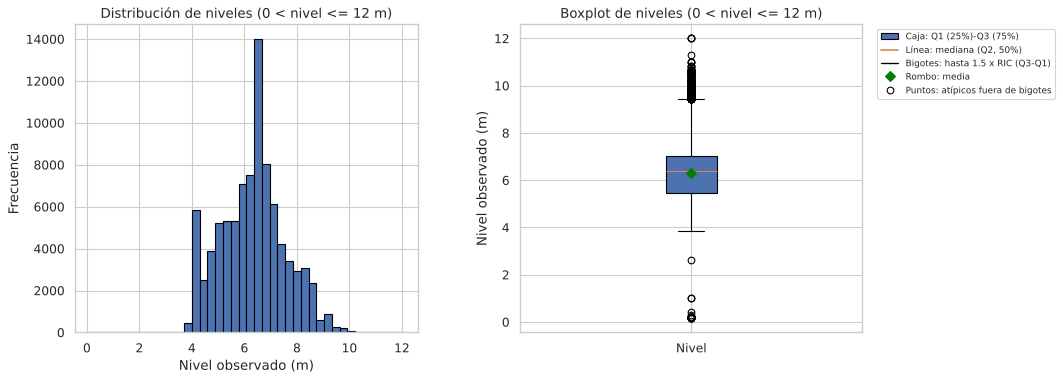

In [ ]:
niveles = df_unico["ValorObservado"]
niveles_en_rango = niveles[(niveles > 0) & (niveles <= 12)]
fuera_de_rango = len(niveles) - len(niveles_en_rango)
print(f"Mediciones fuera del rango graficado (0 o >12 m): {fuera_de_rango:,} ({fuera_de_rango / len(niveles):.2%})")

fig, ejes = plt.subplots(1, 2, figsize=(16, 5))

ejes[0].hist(niveles_en_rango, bins=40, edgecolor="black")
ejes[0].set_title("Distribución de niveles (0 < nivel <= 12 m)")
ejes[0].set_xlabel("Nivel observado (m)")
ejes[0].set_ylabel("Frecuencia")

ejes[1].boxplot(
    niveles_en_rango,
    orientation="vertical",
    showmeans=True,
    patch_artist=True,
    meanprops={"marker": "D", "markerfacecolor": "green", "markeredgecolor": "green"},
)
ejes[1].set_title("Boxplot de niveles (0 < nivel <= 12 m)")
ejes[1].set_ylabel("Nivel observado (m)")
ejes[1].set_xticks([1], ["Nivel"])

elementos_leyenda = [
    Patch(facecolor="C0", edgecolor="black", label="Caja: Q1 (25%)-Q3 (75%)"),
    Line2D([0], [0], color="C1", linewidth=1.5, label="Línea: mediana (Q2, 50%)"),
    Line2D([0], [0], color="black", linewidth=1.2, label="Bigotes: hasta 1.5 x RIC (Q3-Q1)"),
    Line2D([0], [0], marker="D", color="green", linestyle="None", label="Rombo: media"),
    Line2D([0], [0], marker="o", markerfacecolor="white", markeredgecolor="black", linestyle="None", label="Puntos: atípicos fuera de bigotes"),
]
ejes[1].legend(handles=elementos_leyenda, loc="upper left", bbox_to_anchor=(1.03, 1), fontsize=8)

fig.subplots_adjust(right=0.74, wspace=0.3)
plt.show()

El histograma y el boxplot se enfocan en los niveles mayores que 0 y hasta 12 m. Así se amplía la zona donde se concentra la mayoría de las mediciones habituales, aproximadamente entre 4 y 10 m.

El corte de 12 m es exploratorio: ayuda a visualizar la distribución principal, pero no se ha confirmado como máximo físico del río ni como umbral oficial de calidad de IDEAM.

**Registros fuera del rango mostrado**

- 9.420 mediciones iguales a 0.
- 439 mediciones mayores que 12 m.
- Total: 9.859 registros (9,93 %).

Estos registros se excluyen de estos gráficos y del subconjunto validos, pero no se eliminaron de df_unico. Los puntos atípicos que aparecen dentro del rango tampoco se consideran errores automáticamente: el boxplot solo identifica observaciones alejadas de la distribución central.

### 3.2 Valores sospechosos

In [ ]:
limite = 12

print("Valores iguales a 0:", (df_unico["ValorObservado"] == 0).sum())
print(f"Valores mayores a {limite}:", (df_unico["ValorObservado"] > limite).sum())

ceros = df_unico[df_unico["ValorObservado"] == 0]
print(ceros["FechaObservacion"].min(), ceros["FechaObservacion"].max())

display(df_unico.nlargest(15, "ValorObservado"))

Valores iguales a 0: 9420
Valores mayores a 12: 439
2017-10-07 08:52:00 2025-07-22 04:00:00


,FechaObservacion,ValorObservado
27645,2017-12-30 20:08:00,164.0
24131,2017-12-07 03:22:00,149.0
24507,2017-12-16 04:30:00,149.0
24514,2017-12-16 05:06:00,149.0
24613,2017-12-17 04:30:00,149.0
24619,2017-12-17 05:06:00,149.0
24652,2017-12-17 15:06:00,149.0
24662,2017-12-17 18:00:00,149.0
24704,2017-12-18 03:12:00,149.0
24711,2017-12-18 04:30:00,149.0


Se observan valores desde 0 hasta 164 m. Aunque la ficha de IDEAM indica que la unidad es metros, también advierte que los datos son crudos y no han sido validados. Por eso, los extremos requieren revisión antes de clasificarlos como mediciones válidas o errores.

In [ ]:
anomalos = df_unico[(df_unico["ValorObservado"] == 0) | (df_unico["ValorObservado"] > limite)]

print("Total de valores raros:", len(anomalos))
print(f"Porcentaje del total: {len(anomalos) / len(df_unico):.2%}")

anomalos["FechaObservacion"].dt.year.value_counts().sort_index()

Total de valores raros: 9859
Porcentaje del total: 9.93%


,count
FechaObservacion,
2012,1
2017,3192
2018,6653
2024,7
2025,6


In [ ]:
valores_mayores_12 = df_unico.loc[
    df_unico["ValorObservado"] > 12,
    ["FechaObservacion", "ValorObservado"],
].copy()
frecuencia_valores_altos = (
    valores_mayores_12["ValorObservado"]
    .value_counts()
    .rename_axis("nivel_m")
    .reset_index(name="registros")
)

ceros_en_crudo = (df_filtrado["ValorObservado"] == 0).sum()
ceros_deduplicados = (df_unico["ValorObservado"] == 0).sum()
ceros_duplicados_eliminados = ceros_en_crudo - ceros_deduplicados

print("Ceros en CSV cargado:", ceros_en_crudo)
print("Ceros tras quitar duplicados exactos:", ceros_deduplicados)
print("Ceros que eran duplicados exactos:", ceros_duplicados_eliminados)
print("Valores >12 m tras quitar duplicados:", len(valores_mayores_12))
display(frecuencia_valores_altos)

Ceros en CSV cargado: 9427
Ceros tras quitar duplicados exactos: 9420
Ceros que eran duplicados exactos: 7
Valores >12 m tras quitar duplicados: 439


,nivel_m,registros
0,149.00,384
1,131.00,26
2,126.00,6
3,13.00,3
4,26.00,3
5,32.00,2
6,136.00,2
7,38.00,2
8,125.00,2
9,76.00,2


In [ ]:
ceros["FechaObservacion"].dt.to_period("M").value_counts().sort_index()

,count
FechaObservacion,
2017-10,3
2017-11,17
2017-12,3121
2018-01,6266
2024-11,1
2024-12,6
2025-03,1
2025-04,1
2025-06,2


#### Hallazgos sobre valores sospechosos

La ficha oficial de [Nivel Máximo del Río](https://www.datos.gov.co/api/views/vfth-yucv.json) indica que la unidad es metros y define el nivel máximo como el punto más alto registrado durante una hora. También advierte que los datos son crudos, no han sido validados por IDEAM y pueden contener errores de sensor. La ficha no establece 12 m como límite oficial ni define el valor 0 como código de error.

Después de quitar duplicados exactos hay 9.420 ceros y 439 valores mayores a 12 m. Los altos tienen 17 valores distintos: 149 m aparece 384 veces, 131 m 26 veces y 126 m seis veces. Se concentran en diciembre de 2017 y enero de 2018. Los valores de 0 m y los mayores a 12 m no son mediciones que concuerden con el comportamiento normal de un río. Fuera de esos dos meses casi no aparecen ceros (1 o 2 ceros por mes a finales de 2024 y en 2025), por lo cual estos valores atípicos serán considerados errores del sensor.

En el CSV cargado había 9.427 ceros; siete pertenecían a filas duplicadas exactas que se quitaron. Por eso `df_unico` conserva 9.420 ceros. El portal devuelve 9.427 ceros y 439 valores mayores a 12 para la estación en su conjunto, lo mismo que el CSV antes de quitar los duplicados.

Para la limpieza serán eliminados los valores en 0 además de los valores mayores a 12 m, porque los valores normales llegan hasta unos 11 m y de ahí saltan a 13, 26 y 149 m. Además, se observan 19 valores entre 0 y 3 m, que representan un 0,02% de los datos, los cuales se mantendrán porque son muy pocos para cambiar los resultados.

### 3.3 El nivel del río en el tiempo

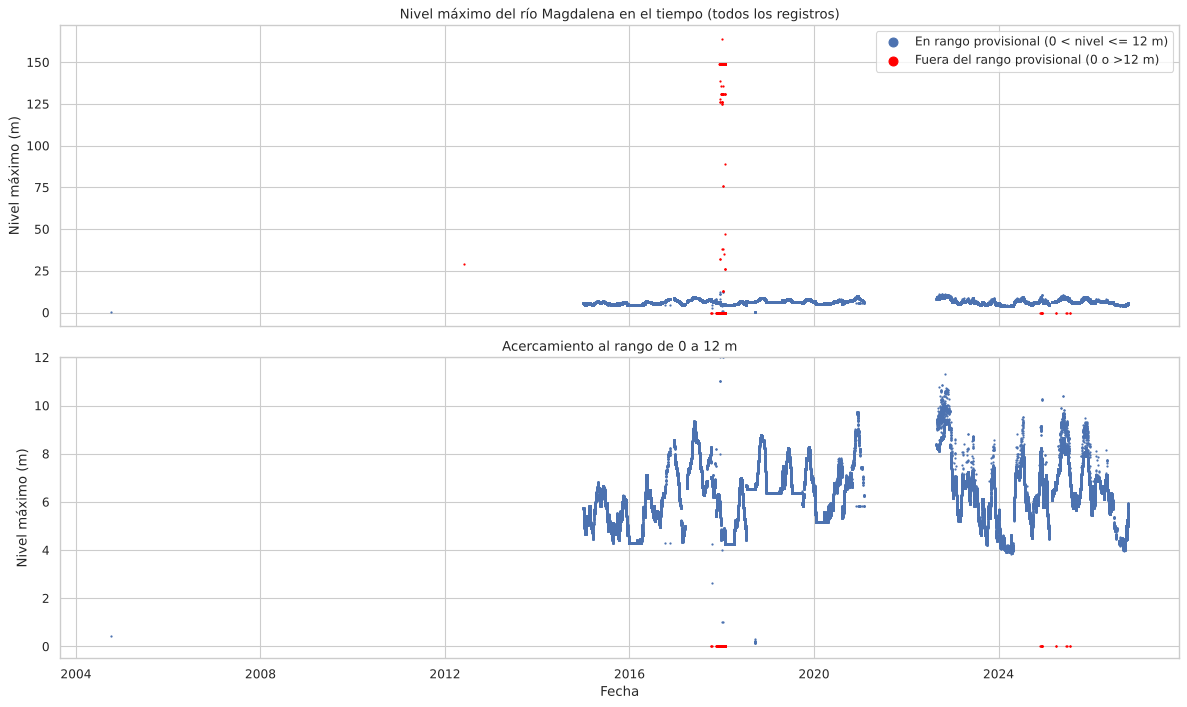

In [ ]:
limite = 12
fuera_criterio = (df_unico["ValorObservado"] == 0) | (df_unico["ValorObservado"] > limite)
validos = df_unico[~fuera_criterio]
anomalos = df_unico[fuera_criterio]

fig, ejes = plt.subplots(2, 1, figsize=(15, 9), sharex=True)

ejes[0].scatter(validos["FechaObservacion"], validos["ValorObservado"], s=1, label="En rango provisional (0 < nivel <= 12 m)")
ejes[0].scatter(anomalos["FechaObservacion"], anomalos["ValorObservado"], s=1, color="red", label="Fuera del rango provisional (0 o >12 m)")
ejes[0].set_title("Nivel máximo del río Magdalena en el tiempo (todos los registros)")
ejes[0].set_ylabel("Nivel máximo (m)")
ejes[0].legend(markerscale=8)

ejes[1].scatter(validos["FechaObservacion"], validos["ValorObservado"], s=1)
ejes[1].scatter(anomalos["FechaObservacion"], anomalos["ValorObservado"], s=1, color="red")
ejes[1].set_ylim(-0.5, 12)
ejes[1].set_title("Acercamiento al rango de 0 a 12 m")
ejes[1].set_xlabel("Fecha")
ejes[1].set_ylabel("Nivel máximo (m)")

plt.tight_layout()
plt.show()

In [ ]:
fechas_validas = validos["FechaObservacion"]

huecos = pd.DataFrame({
    "desde": fechas_validas.shift(1),
    "hasta": fechas_validas,
    "duracion": fechas_validas.diff()
})
huecos = huecos[huecos["duracion"] > pd.Timedelta(days=30)].sort_values("duracion", ascending=False)

display(huecos)

,desde,hasta,duracion
2,2004-10-04 22:54:03,2015-01-01 00:01:00,3740 days 01:06:57
60101,2021-02-02 11:01:00,2022-08-26 21:22:00,570 days 10:21:00


Podemos ver cómo antes del 2015 prácticamente no existen registros a excepción de 2 valores atípicos, además se identifica que existe una falta de registros entre el año 2021 y el año 2022.

Los puntos rojos en 0 están entre diciembre de 2017 y enero de 2018, con datos válidos mezclados. No es un hueco completo, por eso no sale en la tabla. Hay unos pocos ceros más a finales de 2024 y 2025.
Los valores como 149 y 164 también están entre diciembre de 2017 y enero de 2018. Se ve una columna de puntos rojos en esa fecha.

Hay subidas y bajadas entre unos 4 y 10 m que se repiten cada año, es la estacionalidad que se puede observar ya que el nivel del río depende de las temporadas de lluvia y sequías del año.

### 3.4 Comportamiento del nivel según el mes y el año

Para estas gráficas se usan los registros válidos (0 < nivel <= 12 m) desde 2015.

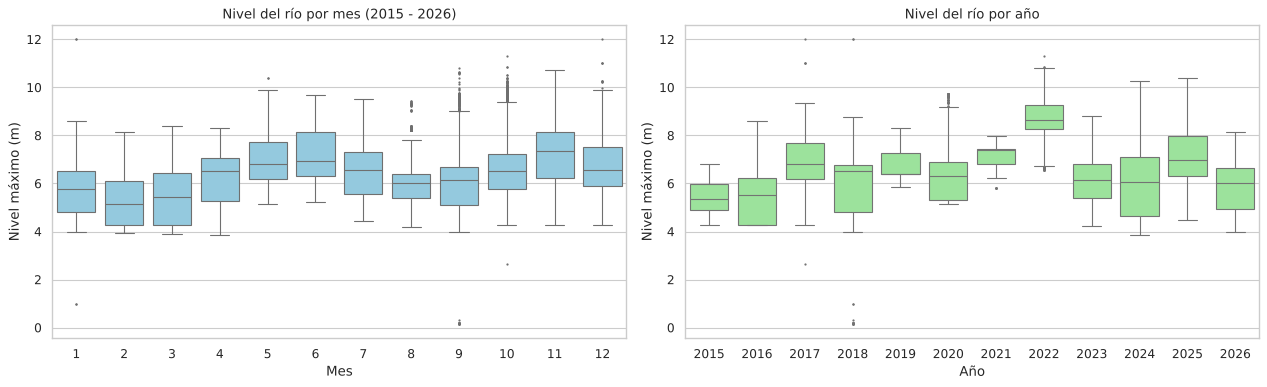

mes,1,2,3,4,5,6,7,8,9,10,11,12
mediana_m,5.77,5.15,5.43,6.54,6.8,6.95,6.55,6.03,6.16,6.53,7.35,6.56


In [ ]:
desde_2015 = validos[validos["FechaObservacion"] >= "2015-01-01"].copy()
desde_2015["mes"] = desde_2015["FechaObservacion"].dt.month
desde_2015["anio"] = desde_2015["FechaObservacion"].dt.year

fig, ejes = plt.subplots(1, 2, figsize=(16, 5))

sns.boxplot(data=desde_2015, x="mes", y="ValorObservado", ax=ejes[0], color="skyblue", fliersize=1)
ejes[0].set_title("Nivel del río por mes (2015 - 2026)")
ejes[0].set_xlabel("Mes")
ejes[0].set_ylabel("Nivel máximo (m)")

sns.boxplot(data=desde_2015, x="anio", y="ValorObservado", ax=ejes[1], color="lightgreen", fliersize=1)
ejes[1].set_title("Nivel del río por año")
ejes[1].set_xlabel("Año")
ejes[1].set_ylabel("Nivel máximo (m)")

plt.tight_layout()
plt.show()

display(desde_2015.groupby("mes")["ValorObservado"].median().round(2).to_frame("mediana_m").T)

Encontramos que hay diferencias de niveles a lo largo de los años formando una tendencia, las más altas en noviembre 7,35 m y mayo-junio (6,8-6,95 m); las más bajas en febrero (5,15 m) y marzo 5,43 m, y otra baja en agosto 6,03 m.

Coincide con las dos temporadas de lluvias del año en Colombia y estas epocas del año nos ayuda a predecir el nivel del río.

2022 fue el más alto con una mediana cercana a 8,6 m y 2015-2016 los más bajos con alrededor de 5,5 m. Esto coincide con los fenomenos de la Niña (lluvias) y el Niño (sequía).

## 4. Preparación para modelos

El entrenamiento parte únicamente de `filtrada.csv`, construida con registros deduplicados cuyo nivel cumple 0 < nivel <= 12 m. Los niveles mayores a 12 m y los ceros no se usan en predictores ni objetivos del modelo. El corte de 12 m es una decisión exploratoria, no un criterio oficial de calidad del IDEAM.

El archivo contiene una fila por origen, los predictores y los objetivos de máximo observado para cuatro horizontes: 8 horas, 1 día, 3 días y 1 semana. Cada horizonte se entrena y evalúa por separado.

### 4.1 Variables seleccionadas

Cada fila es una lectura (origen). Los 11 predictores son:
- `nivel_t`: el nivel en ese momento.
- `dia_anio_sin` y `dia_anio_cos`: la época del año.
- `maximo_pasado_ultimas`: el nivel más alto de las últimas 8 h, 1 día, 3 días y 1 semana, usando solo lecturas anteriores al origen.
- `delta_pasado`: nivel actual menos cada máximo pasado. Si es muy negativo, el río viene bajando desde un pico; si es cercano a 0, está en su punto más alto o subiendo.

Nuestro objetivo es predecir el nivel más alto de las próximas 8 h, 24 h, 72 h y 168 h.

Los modelos no predicen el máximo directamente, sino cuánto va a cambiar (máximo futuro − `nivel_t`); después se le suma `nivel_t` para volver a metros. la razón es que el río cambia despacio, así que es más fácil aprender el cambio que el nivel completo; además los árboles no pueden predecir valores que no vieron en entrenamiento, y con el cambio ese problema se reduce.

### 4.2 La época del año como seno y coseno

como se vio que el nivel depende de la época del año entonces conviene dársela al modelo, pero si se usa el día del año como número de 1 a 365, el modelo cree que el 31 de diciembre (365) y el 1 de enero (1) están muy lejos, cuando en realidad son días seguidos ya que el año es un ciclo.

La solución es poner los días en un círculo, como las horas de un reloj, y describir cada día con dos números: el seno y el coseno de su ángulo (2π · día / 365,25).

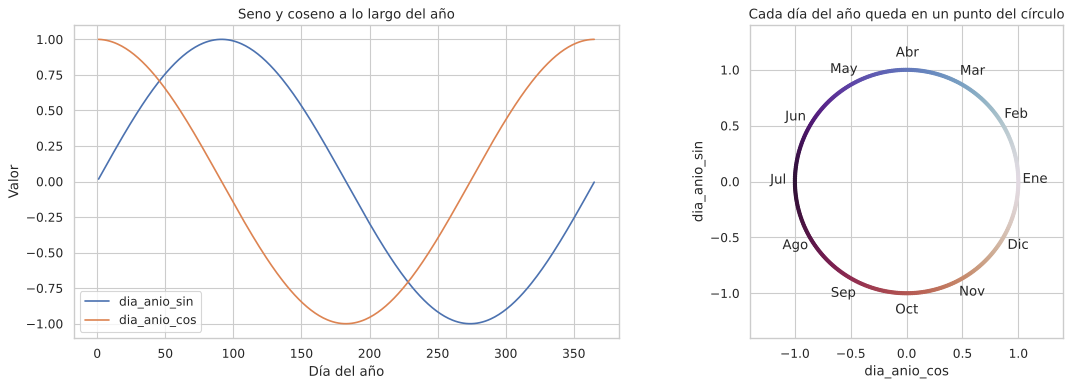

In [ ]:
dias = np.arange(1, 366)
angulo = 2 * np.pi * dias / 365.25
nombres_meses = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

fig, ejes = plt.subplots(1, 2, figsize=(15, 5))

ejes[0].plot(dias, np.sin(angulo), label="dia_anio_sin")
ejes[0].plot(dias, np.cos(angulo), label="dia_anio_cos")
ejes[0].set_title("Seno y coseno a lo largo del año")
ejes[0].set_xlabel("Día del año")
ejes[0].set_ylabel("Valor")
ejes[0].legend()

ejes[1].scatter(np.cos(angulo), np.sin(angulo), c=dias, cmap="twilight", s=8)
for numero_mes, nombre in enumerate(nombres_meses, start=1):
    dia = pd.Timestamp(2025, numero_mes, 1).dayofyear
    a = 2 * np.pi * dia / 365.25
    ejes[1].annotate(nombre, (np.cos(a) * 1.15, np.sin(a) * 1.15), ha="center", va="center")
ejes[1].set_title("Cada día del año queda en un punto del círculo")
ejes[1].set_xlabel("dia_anio_cos")
ejes[1].set_ylabel("dia_anio_sin")
ejes[1].set_aspect("equal")
ejes[1].set_xlim(-1.4, 1.4)
ejes[1].set_ylim(-1.4, 1.4)

plt.tight_layout()
plt.show()

con los dos juntos, cada día es un punto distinto del círculo, y diciembre queda pegado a enero. Se llaman `dia_anio` porque se calculan con el día del año, no con el mes, asi es más preciso.

### 4.3 Separación 80/20

Para cada horizonte, los datos de `filtrada.csv` se ordenan por fecha y se toma como inicio de prueba el corte del 80 %. Se eliminan del entrenamiento los orígenes cuya ventana objetivo alcanza el comienzo de prueba, evitando que el entrenamiento use niveles del periodo de prueba. La prueba se reserva para reportar las métricas finales.

## 5. Construcción de `filtrada.csv`

Esta celda construye, para cada lectura válida (origen): 1) `nivel_t`; 2) seno y coseno del día del año; 3) el máximo de las últimas 8, 24, 72 y 168 h; 4) los deltas; 5) los objetivos (máximo de las próximas 8, 24, 72 y 168 h).

Usamos una ventana deslizante hacia atras y hacia delante se corre una lectura y si en la ventana futura no hay ningún objetivo entonces esa fila no se usa para ese horizonte.

In [ ]:
horizontes_horas = [8, 24, 72, 168]
ruta_filtrada = Path.cwd() / "filtrada.csv"

# 1. Registros válidos (0 < nivel <= 12 m), ordenados por fecha
mascara_modelo = df_unico["ValorObservado"].gt(0) & df_unico["ValorObservado"].le(12)
df_modelo = (
    df_unico.loc[mascara_modelo]
    .sort_values("FechaObservacion")
    .reset_index(drop=True)
)
print("Registros usados (0 < nivel <= 12 m):", len(df_modelo))

fechas = df_modelo["FechaObservacion"]
fechas_ns = fechas.to_numpy(dtype="datetime64[ns]").view("int64")
niveles_array = df_modelo["ValorObservado"].to_numpy(dtype=float)

predictores = pd.DataFrame(index=df_modelo.index)
predictores["nivel_t"] = niveles_array

# 2. Época del año como seno y coseno del día del año
dia_del_anio = fechas.dt.dayofyear
predictores["dia_anio_sin"] = np.sin(2 * np.pi * dia_del_anio / 365.25)
predictores["dia_anio_cos"] = np.cos(2 * np.pi * dia_del_anio / 365.25)

# 3. Nivel más alto de las últimas h horas (solo lecturas ANTERIORES al origen)
for horizonte in horizontes_horas:
    duracion_ns = pd.Timedelta(hours=horizonte).value
    inicios = np.searchsorted(fechas_ns, fechas_ns - duracion_ns, side="left")
    maximo_pasado = np.empty(len(df_modelo))
    for posicion, inicio in enumerate(inicios):
        if inicio < posicion:
            maximo_pasado[posicion] = niveles_array[inicio:posicion].max()
        else:
            maximo_pasado[posicion] = niveles_array[posicion]
    predictores[f"maximo_pasado_ultimas_{horizonte}h"] = maximo_pasado

# 4. Diferencia entre el nivel actual y cada máximo pasado
for horizonte in horizontes_horas:
    predictores[f"delta_pasado_{horizonte}h"] = (
        predictores["nivel_t"] - predictores[f"maximo_pasado_ultimas_{horizonte}h"]
    )

# 5. Objetivos: nivel más alto de las próximas h horas
objetivos = pd.DataFrame(index=df_modelo.index)
resumen_horizontes = []
for horizonte in horizontes_horas:
    duracion_ns = pd.Timedelta(hours=horizonte).value
    inicios = np.searchsorted(fechas_ns, fechas_ns, side="right")
    finales = np.searchsorted(fechas_ns, fechas_ns + duracion_ns, side="right")
    objetivo = np.full(len(df_modelo), np.nan)
    for posicion, (inicio, fin) in enumerate(zip(inicios, finales)):
        if inicio < fin:
            objetivo[posicion] = niveles_array[inicio:fin].max()
    nombre_objetivo = f"maximo_observado_proximas_{horizonte}h"
    objetivos[nombre_objetivo] = objetivo
    resumen_horizontes.append({
        "horizonte_horas": horizonte,
        "muestras": int(objetivos[nombre_objetivo].notna().sum()),
        "origenes_sin_lectura_futura": int(objetivos[nombre_objetivo].isna().sum()),
    })

columnas_predictores = list(predictores.columns)
columnas_objetivo = list(objetivos.columns)

filtrada = pd.concat(
    [fechas.rename("fecha_origen"), predictores, objetivos],
    axis=1,
).loc[objetivos.notna().any(axis=1)].reset_index(drop=True)
filtrada.to_csv(ruta_filtrada, index=False, date_format="%Y-%m-%d %H:%M:%S")

print("Archivo generado:", ruta_filtrada.name)
print("Filas:", len(filtrada), "| Predictores:", len(columnas_predictores))
display(pd.DataFrame(resumen_horizontes))
display(filtrada.head())

Registros usados (0 < nivel <= 12 m): 89444
Archivo generado: filtrada.csv
Filas: 89436 | Predictores: 11


,horizonte_horas,muestras,origenes_sin_lectura_futura
0,8,89225,219
1,24,89380,64
2,72,89422,22
3,168,89436,8


,fecha_origen,nivel_t,dia_anio_sin,dia_anio_cos,maximo_pasado_ultimas_8h,maximo_pasado_ultimas_24h,maximo_pasado_ultimas_72h,maximo_pasado_ultimas_168h,delta_pasado_8h,delta_pasado_24h,delta_pasado_72h,delta_pasado_168h,maximo_observado_proximas_8h,maximo_observado_proximas_24h,maximo_observado_proximas_72h,maximo_observado_proximas_168h
0,2015-01-01 00:01:00,5.72,0.017202,0.999852,5.72,5.72,5.72,5.72,0.00,0.00,0.00,0.00,5.73,5.76,5.76,5.76
1,2015-01-01 01:11:00,5.72,0.017202,0.999852,5.72,5.72,5.72,5.72,0.00,0.00,0.00,0.00,5.73,5.76,5.76,5.76
2,2015-01-01 02:52:00,5.73,0.017202,0.999852,5.72,5.72,5.72,5.72,0.01,0.01,0.01,0.01,5.74,5.76,5.76,5.76
3,2015-01-01 03:12:00,5.72,0.017202,0.999852,5.73,5.73,5.73,5.73,-0.01,-0.01,-0.01,-0.01,5.74,5.76,5.76,5.76
4,2015-01-01 04:29:00,5.73,0.017202,0.999852,5.73,5.73,5.73,5.73,0.00,0.00,0.00,0.00,5.75,5.76,5.76,5.76


Se usan 89.444 registros entre 0 y 12 m y quedan 89.436 filas con 11 predictores.

Para calcular los objetivos, se busca el nivel más alto entre las lecturas de las horas siguientes. Si en esas horas el sensor no registró nada, ese objetivo queda vacío por lo que esas filas no se borran, solo no se usan en ese horizonte.

In [ ]:
display(filtrada[columnas_predictores + columnas_objetivo].describe().round(3).T)

,count,mean,std,min,25%,50%,75%,max
nivel_t,89436.0,6.316,1.219,0.15,5.450,6.390,7.040,12.00
dia_anio_sin,89436.0,0.002,0.709,-1.00,-0.716,0.017,0.711,1.00
dia_anio_cos,89436.0,-0.026,0.705,-1.00,-0.720,-0.051,0.678,1.00
maximo_pasado_ultimas_8h,89436.0,6.365,1.274,0.18,5.460,6.390,7.090,12.00
maximo_pasado_ultimas_24h,89436.0,6.441,1.343,3.98,5.500,6.390,7.140,12.00
maximo_pasado_ultimas_72h,89436.0,6.565,1.419,4.04,5.580,6.400,7.370,12.00
maximo_pasado_ultimas_168h,89436.0,6.723,1.481,4.08,5.730,6.530,7.670,12.00
delta_pasado_8h,89436.0,-0.050,0.239,-7.25,-0.030,-0.010,0.000,7.20
delta_pasado_24h,89436.0,-0.125,0.354,-11.00,-0.090,-0.020,0.000,7.16
delta_pasado_72h,89436.0,-0.250,0.493,-11.00,-0.260,-0.070,0.000,7.14


- Los máximos pasados y los objetivos tienen promedios parecidos (6,4 a 6,7 m) y crecen con la ventana
- Los deltas casi siempre son negativos o 0

### 5.1 Matriz de correlación

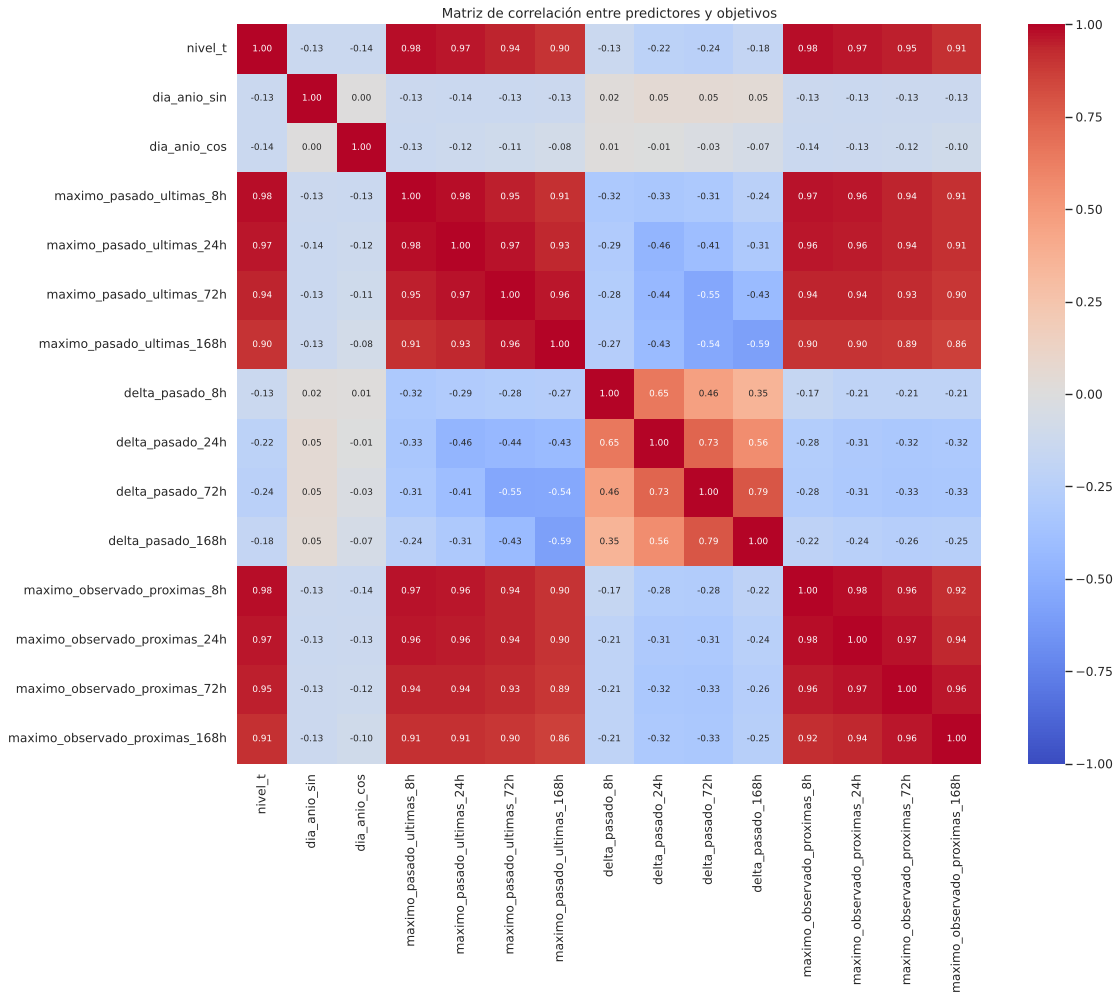

In [ ]:
correlacion = filtrada[columnas_predictores + columnas_objetivo].corr()

plt.figure(figsize=(15, 12))
sns.heatmap(correlacion, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, annot_kws={"size": 8})
plt.title("Matriz de correlación entre predictores y objetivos")
plt.show()

- `nivel_t` y los máximos pasados están casi perfectamente relacionados entre sí y con los objetivos.
- La correlación con los objetivos baja a medida que el horizonte es más largo por lo que se puede pensar que predecir una semana es más difícil que 8 horas.
- Los deltas tienen correlación baja con los objetivos, esto es porque la matriz lo compara con el nivel máximo, no con el cambio. Un delta de −0,5 m puede pasar con el río en 5 m o en 9 m, así que no dice nada sobre el nivel en sí.
- Como muchos predictores se parecen tanto entre sí, en la regresión lineal se usa Ridge, que maneja mejor variables muy correlacionadas.

## 6. Preparación y partición temporal

Después de generar `filtrada.csv`, en esta celda se hace la separación 80/20 descrita en la sección 4.3 y se crean los pliegues para la validación cruzada.

GridSearchCV necesita validación cruzada, pero con datos en el tiempo no se puede usar la normal, que mezcla al azar, porque el modelo entrenaría con el futuro, por eso se usa `TimeSeriesSplit` para construir 3 pliegues.

In [ ]:
datos_filtrados = pd.read_csv(ruta_filtrada, parse_dates=["fecha_origen"])
particiones_por_horizonte = {}

for horizonte in horizontes_horas:
    columna_objetivo = f"maximo_observado_proximas_{horizonte}h"
    datos = (
        datos_filtrados
        .dropna(subset=[columna_objetivo])
        .sort_values("fecha_origen")
        .reset_index(drop=True)
    )
    posicion_corte = int(len(datos) * 0.8)
    fecha_inicio_prueba = datos.loc[posicion_corte, "fecha_origen"]
    duracion_horizonte = pd.Timedelta(hours=horizonte)

    mascara_entrenamiento = datos["fecha_origen"] + duracion_horizonte < fecha_inicio_prueba
    entrenamiento = datos.loc[mascara_entrenamiento].reset_index(drop=True)
    prueba = datos.loc[datos["fecha_origen"] >= fecha_inicio_prueba].reset_index(drop=True)

    particiones_por_horizonte[horizonte] = {
        "entrenamiento": entrenamiento,
        "prueba": prueba,
        "fecha_inicio_prueba": fecha_inicio_prueba,
    }
    print(
        f"Horizonte {horizonte} h | corte: {fecha_inicio_prueba} | "
        f"entrenamiento: {len(entrenamiento)} | prueba: {len(prueba)} | "
        f"purgadas: {int((datos['fecha_origen'] < fecha_inicio_prueba).sum() - len(entrenamiento))}"
    )


def crear_pliegues_temporales(entrenamiento, horizonte, n_splits=3):
    duracion = pd.Timedelta(hours=horizonte)
    pliegues = []
    for indices_entrenamiento, indices_validacion in TimeSeriesSplit(n_splits=n_splits).split(entrenamiento):
        inicio_validacion = entrenamiento.iloc[indices_validacion]["fecha_origen"].min()
        fechas_entrenamiento = entrenamiento.iloc[indices_entrenamiento]["fecha_origen"]
        indices_entrenamiento = indices_entrenamiento[
            (fechas_entrenamiento + duracion < inicio_validacion).to_numpy()
        ]
        pliegues.append((indices_entrenamiento, indices_validacion))
    return pliegues

Horizonte 8 h | corte: 2025-01-25 16:58:00 | entrenamiento: 71366 | prueba: 17845 | purgadas: 14
Horizonte 24 h | corte: 2025-01-25 09:56:00 | entrenamiento: 71459 | prueba: 17876 | purgadas: 45
Horizonte 72 h | corte: 2025-01-25 10:53:00 | entrenamiento: 71396 | prueba: 17885 | purgadas: 141
Horizonte 168 h | corte: 2025-01-25 10:27:00 | entrenamiento: 71221 | prueba: 17888 | purgadas: 327


El corte de prueba cae el 25 de enero de 2025 en los 4 horizontes, tenemos unas 71.400 filas para entrenamiento y unas 17.870 para prueba en cada horizonte y las purgadas son muy pocas comparadas con las 71 mil, así que no se pierden datos importantes.

### 6.1 Funciones para entrenar y evaluar los modelos

Se crearan funciones para no repetir el mismo código en los 10 modelos y para que todos se evalúen exactamente igual.
- `calcular_metricas`: **MAE** (error promedio en metros), **RMSE** (castiga más los errores grandes), **R²** (qué parte de la variación del nivel explica el modelo; 1 es perfecto) y **MAPE** (error promedio en porcentaje del nivel real).
- `entrenar_modelo_inicial`: entrena una configuración fija en cada horizonte con el 80 % y la evalúa en la prueba.
- `buscar_hiperparametros`: hace GridSearchCV con los pliegues temporales purgados, escoge por el menor MAE de validación y evalúa el mejor modelo una sola vez en la prueba.
- En las dos, el modelo aprende el cambio (máximo futuro − `nivel_t`) y la predicción final es `nivel_t` + cambio predicho.
- `comparar_con_lineas_base`: muestra por horizonte el MAE del modelo frente a la mejor línea base y la mejora en % (positivo = el modelo es mejor; negativo = la regla simple es mejor).

In [ ]:
resultados = {}            # nombre del modelo -> tabla de métricas en prueba
modelos_entrenados = {}    # nombre del modelo -> {horizonte: modelo}


def calcular_metricas(real, prediccion):
    return {
        "MAE_m": mean_absolute_error(real, prediccion),
        "RMSE_m": mean_squared_error(real, prediccion) ** 0.5,
        "R2": r2_score(real, prediccion),
        "MAPE_%": mean_absolute_percentage_error(real, prediccion) * 100,
    }


def describir(parametros):
    return ", ".join(f"{nombre.split('__')[-1]}={valor}" for nombre, valor in parametros.items())


def entrenar_modelo_inicial(nombre, crear_modelo):
    """Entrena una configuración fija en cada horizonte y la evalúa en prueba.
    El modelo aprende el CAMBIO (máximo futuro - nivel_t) y luego se le suma nivel_t."""
    filas, modelos = [], {}
    for horizonte, particion in particiones_por_horizonte.items():
        entrenamiento, prueba = particion["entrenamiento"], particion["prueba"]
        objetivo = f"maximo_observado_proximas_{horizonte}h"

        modelo = crear_modelo()
        modelo.fit(entrenamiento[columnas_predictores], entrenamiento[objetivo] - entrenamiento["nivel_t"])
        prediccion = prueba["nivel_t"] + modelo.predict(prueba[columnas_predictores])

        filas.append({
            "modelo": nombre,
            "horizonte_horas": horizonte,
            "muestras_prueba": len(prueba),
            **calcular_metricas(prueba[objetivo], prediccion),
        })
        modelos[horizonte] = modelo

    tabla = pd.DataFrame(filas)
    resultados[nombre] = tabla
    modelos_entrenados[nombre] = modelos
    return tabla


def buscar_hiperparametros(nombre, estimador, parametros):
    """GridSearchCV con pliegues temporales purgados en cada horizonte.
    Escoge por MAE de validación y evalúa el mejor modelo una sola vez en prueba."""
    filas_busqueda, filas_mejor, modelos = [], [], {}
    for horizonte, particion in particiones_por_horizonte.items():
        entrenamiento, prueba = particion["entrenamiento"], particion["prueba"]
        objetivo = f"maximo_observado_proximas_{horizonte}h"

        busqueda = GridSearchCV(
            estimador,
            param_grid=parametros,
            scoring="neg_mean_absolute_error",
            cv=crear_pliegues_temporales(entrenamiento, horizonte),
            n_jobs=-1,
        )
        busqueda.fit(entrenamiento[columnas_predictores], entrenamiento[objetivo] - entrenamiento["nivel_t"])
        modelo = busqueda.best_estimator_
        prediccion = prueba["nivel_t"] + modelo.predict(prueba[columnas_predictores])

        for parametros_probados, mae_cv in zip(
            busqueda.cv_results_["params"], -busqueda.cv_results_["mean_test_score"]
        ):
            filas_busqueda.append({
                "horizonte_horas": horizonte,
                **{clave.split("__")[-1]: valor for clave, valor in parametros_probados.items()},
                "configuracion": describir(parametros_probados),
                "MAE_CV_m": mae_cv,
            })
        filas_mejor.append({
            "modelo": nombre,
            "horizonte_horas": horizonte,
            "mejor_configuracion": describir(busqueda.best_params_),
            "MAE_CV_m": -busqueda.best_score_,
            "muestras_prueba": len(prueba),
            **calcular_metricas(prueba[objetivo], prediccion),
        })
        modelos[horizonte] = modelo

    tabla_mejor = pd.DataFrame(filas_mejor)
    resultados[nombre] = tabla_mejor.drop(columns=["mejor_configuracion", "MAE_CV_m"])
    modelos_entrenados[nombre] = modelos
    return tabla_mejor, pd.DataFrame(filas_busqueda)


def mostrar_top(tabla_busqueda, cantidad=5):
    display(
        tabla_busqueda.sort_values(["horizonte_horas", "MAE_CV_m"])
        .groupby("horizonte_horas").head(cantidad)
        [["horizonte_horas", "configuracion", "MAE_CV_m"]]
        .round(4)
    )


def graficar_top(tabla_busqueda, titulo):
    fig, ejes = plt.subplots(2, 2, figsize=(16, 10))
    for eje, (horizonte, candidatos) in zip(ejes.flat, tabla_busqueda.groupby("horizonte_horas")):
        mejores = candidatos.nsmallest(10, "MAE_CV_m")
        eje.barh(mejores["configuracion"], mejores["MAE_CV_m"])
        eje.invert_yaxis()
        eje.set_xlim(mejores["MAE_CV_m"].min() * 0.98, mejores["MAE_CV_m"].max() * 1.01)
        eje.set_title(f"{titulo} - horizonte {horizonte} h")
        eje.set_xlabel("MAE de validación (m), menor es mejor")
    fig.tight_layout()
    plt.show()


def comparar_con_lineas_base(*nombres):
    """Muestra, por horizonte, el MAE de los modelos frente a la mejor línea base."""
    bases = pd.concat(
        [resultados["persistencia_pura"], resultados["persistencia_maximo_pasado"]],
        ignore_index=True,
    )
    mejor_base = bases.loc[bases.groupby("horizonte_horas")["MAE_m"].idxmin()]
    tabla = mejor_base[["horizonte_horas", "modelo", "MAE_m"]].rename(
        columns={"modelo": "mejor_linea_base", "MAE_m": "MAE_linea_base_m"}
    )
    for nombre in nombres:
        tabla = tabla.merge(
            resultados[nombre][["horizonte_horas", "MAE_m"]].rename(columns={"MAE_m": f"MAE_{nombre}_m"}),
            on="horizonte_horas",
        )
        tabla[f"mejora_{nombre}_%"] = (
            (tabla["MAE_linea_base_m"] - tabla[f"MAE_{nombre}_m"]) / tabla["MAE_linea_base_m"] * 100
        )
    display(tabla.reset_index(drop=True).round(4))

## 7. Líneas base de referencia

Antes de los modelos se calculan dos reglas simples, sin entrenar nada, sobre la misma prueba:
- `persistencia_pura`: el máximo de las próximas h horas será igual al nivel actual.
- `persistencia_maximo_pasado`: el máximo de las próximas h horas será igual al máximo de las últimas h horas.

y decimos que un modelo vale pena si se equivoca menos que la mejor de las 2.

In [ ]:
for nombre, columna_prediccion in [
    ("persistencia_pura", lambda h: "nivel_t"),
    ("persistencia_maximo_pasado", lambda h: f"maximo_pasado_ultimas_{h}h"),
]:
    filas = []
    for horizonte, particion in particiones_por_horizonte.items():
        prueba = particion["prueba"]
        objetivo = f"maximo_observado_proximas_{horizonte}h"
        filas.append({
            "modelo": nombre,
            "horizonte_horas": horizonte,
            "muestras_prueba": len(prueba),
            **calcular_metricas(prueba[objetivo], prueba[columna_prediccion(horizonte)]),
        })
    resultados[nombre] = pd.DataFrame(filas)

display(
    pd.concat([resultados["persistencia_pura"], resultados["persistencia_maximo_pasado"]])
    .sort_values(["horizonte_horas", "MAE_m"])
    .reset_index(drop=True)
    .round(4)
)

,modelo,horizonte_horas,muestras_prueba,MAE_m,RMSE_m,R2,MAPE_%
0,persistencia_pura,8,17845,0.1144,0.3092,0.9411,1.3760
1,persistencia_maximo_pasado,8,17845,0.1480,0.3458,0.9263,1.8696
2,persistencia_maximo_pasado,24,17876,0.2187,0.3933,0.9196,2.8472
3,persistencia_pura,24,17876,0.2315,0.4509,0.8944,2.7855
4,persistencia_maximo_pasado,72,17885,0.2693,0.4041,0.9256,3.7092
5,persistencia_pura,72,17885,0.3995,0.6119,0.8294,4.8814
6,persistencia_maximo_pasado,168,17888,0.3895,0.5290,0.8795,5.3908
7,persistencia_pura,168,17888,0.5651,0.7707,0.7442,6.9796



Estas son las referencias que los modelos tienen que superar.

## 8. Regresión lineal multivariada (Ridge)

### 8.1 Modelo inicial de Ridge

Ridge es una regresión lineal multivariada con penalización: el parámetro `alpha` castiga los coeficientes grandes. Sirve aquí porque los predictores están muy correlacionado.

Usamos StandardScaler dentro de un pipeline porque las variables tienen escalas diferentes y solo le calcula en los datos de entrenamientos.

Para esta primera configuracion usamos alpha = 1.

In [ ]:
tabla_ridge_inicial = entrenar_modelo_inicial(
    "ridge_inicial",
    lambda: Pipeline([("escalador", StandardScaler()), ("ridge", Ridge(alpha=1.0))]),
)
display(tabla_ridge_inicial.round(4))
comparar_con_lineas_base("ridge_inicial")

,modelo,horizonte_horas,muestras_prueba,MAE_m,RMSE_m,R2,MAPE_%
0,ridge_inicial,8,17845,0.1269,0.2718,0.9545,1.5783
1,ridge_inicial,24,17876,0.2035,0.3356,0.9415,2.5776
2,ridge_inicial,72,17885,0.2751,0.3829,0.9332,3.5810
3,ridge_inicial,168,17888,0.3433,0.4446,0.9148,4.5419


,horizonte_horas,mejor_linea_base,MAE_linea_base_m,MAE_ridge_inicial_m,mejora_ridge_inicial_%
0,8,persistencia_pura,0.1144,0.1269,-10.9170
1,24,persistencia_maximo_pasado,0.2187,0.2035,6.9395
2,72,persistencia_maximo_pasado,0.2693,0.2751,-2.1367
3,168,persistencia_maximo_pasado,0.3895,0.3433,11.8670


Podemos observar que supera a la línea base a 24h por un 6,9% y 168h por un 11,9% ademas pierde a 8h por un −10,9 % y a 72h en un −2,1 %, y en RMSE sí mejora a la línea base en los 4 horizontes

### 8.2 Búsqueda de hiperparámetros de Ridge con GridSearchCV

Se prueban 50 combinaciones, 25 valores de alpha entre 0,001 y 10⁹ (escala logarítmica) × `fit_intercept` True/False.
Con alpha muy pequeño, Ridge es prácticamente una regresión lineal sin penalización, así que la búsqueda también cubre ese caso, pero con alpha muy grande los coeficientes quedan casi en 0 y el modelo predice siempre el mismo cambio. Sin intercepto, eso es predecir cambio 0, o sea, la persistencia pura.

,horizonte_horas,configuracion,MAE_CV_m
49,8,"alpha=1000000000.0, fit_intercept=False",0.0589
47,8,"alpha=316227766.01683795, fit_intercept=False",0.0589
45,8,"alpha=100000000.0, fit_intercept=False",0.0589
43,8,"alpha=31622776.60168379, fit_intercept=False",0.0589
41,8,"alpha=10000000.0, fit_intercept=False",0.0590
91,24,"alpha=10000000.0, fit_intercept=False",0.1264
93,24,"alpha=31622776.60168379, fit_intercept=False",0.1264
95,24,"alpha=100000000.0, fit_intercept=False",0.1264
97,24,"alpha=316227766.01683795, fit_intercept=False",0.1264
99,24,"alpha=1000000000.0, fit_intercept=False",0.1264


,modelo,horizonte_horas,mejor_configuracion,MAE_CV_m,muestras_prueba,MAE_m,RMSE_m,R2,MAPE_%
0,ridge_ajustado,8,"alpha=1000000000.0, fit_intercept=False",0.0589,17845,0.1144,0.3092,0.9411,1.3760
1,ridge_ajustado,24,"alpha=10000000.0, fit_intercept=False",0.1264,17876,0.2302,0.4476,0.8959,2.7746
2,ridge_ajustado,72,"alpha=3162.2776601683795, fit_intercept=True",0.2368,17885,0.2759,0.3831,0.9331,3.5907
3,ridge_ajustado,168,"alpha=10000.0, fit_intercept=True",0.3774,17888,0.3460,0.4457,0.9144,4.5758


,horizonte_horas,mejor_linea_base,MAE_linea_base_m,MAE_ridge_inicial_m,mejora_ridge_inicial_%,MAE_ridge_ajustado_m,mejora_ridge_ajustado_%
0,8,persistencia_pura,0.1144,0.1269,-10.9170,0.1144,0.0030
1,24,persistencia_maximo_pasado,0.2187,0.2035,6.9395,0.2302,-5.2420
2,72,persistencia_maximo_pasado,0.2693,0.2751,-2.1367,0.2759,-2.4468
3,168,persistencia_maximo_pasado,0.3895,0.3433,11.8670,0.3460,11.1701


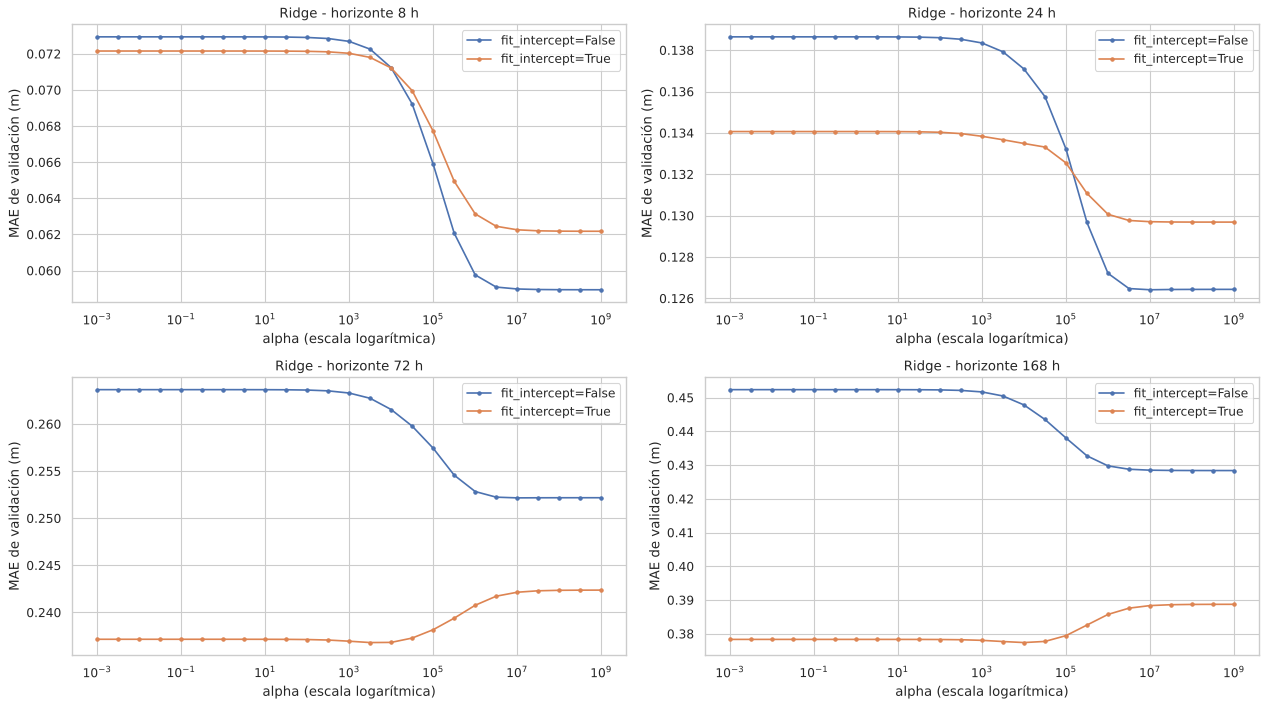

In [ ]:
parametros_ridge = {
    "ridge__alpha": np.logspace(-3, 9, 25),
    "ridge__fit_intercept": [True, False],
}
mejor_ridge, busqueda_ridge = buscar_hiperparametros(
    "ridge_ajustado",
    Pipeline([("escalador", StandardScaler()), ("ridge", Ridge())]),
    parametros_ridge,
)
mostrar_top(busqueda_ridge)
display(mejor_ridge.round(4))
comparar_con_lineas_base("ridge_inicial", "ridge_ajustado")

fig, ejes = plt.subplots(2, 2, figsize=(16, 9))
for eje, (horizonte, candidatos) in zip(ejes.flat, busqueda_ridge.groupby("horizonte_horas")):
    for intercepto, grupo in candidatos.groupby("fit_intercept"):
        eje.plot(grupo["alpha"], grupo["MAE_CV_m"], marker="o", markersize=3, label=f"fit_intercept={intercepto}")
    eje.set_xscale("log")
    eje.set_title(f"Ridge - horizonte {horizonte} h")
    eje.set_xlabel("alpha (escala logarítmica)")
    eje.set_ylabel("MAE de validación (m)")
    eje.legend()
fig.tight_layout()
plt.show()

A 8 y 24 horas el mejor es alpha enorme sin intercepto y el modelo termina prediciendo que "no va a cambiar". Por eso a 8h el Ridge ajustado da exactamente lo mismo que la persistencia pura (0,1144 m). En la gráfica se ve que el error de validación baja y se queda plano a partir de alpha ≈ 10⁷, así que no sirve ampliar más la grilla.

Como conclusion tenemos que para un modelo lineal, a corto plazo lo mejor es no predecir cambio.

A 72 y 168 horas gana alpha de 10³ a 10⁴ con intercepto y en las 168h mejora a la línea base en un 11,2 %.

## 9. Árbol de decisión

### 9.1 Modelo inicial de árbol de decisión

> ✏️ **Para redactar** (borrar esta nota y escribir el análisis con sus palabras):
>
> - Un árbol de decisión divide los datos con preguntas sobre las variables (por ejemplo, "¿el delta de 72 h es menor que −0,69?") y en cada hoja predice el promedio del cambio de esas filas.
> - Configuración inicial: `max_depth = 6` (máximo 6 preguntas seguidas) y `min_samples_leaf = 20` (mínimo 20 filas por hoja).

In [ ]:
tabla_arbol_inicial = entrenar_modelo_inicial(
    "arbol_inicial",
    lambda: DecisionTreeRegressor(max_depth=6, min_samples_leaf=20, random_state=42),
)
display(tabla_arbol_inicial.round(4))
comparar_con_lineas_base("arbol_inicial")

,modelo,horizonte_horas,muestras_prueba,MAE_m,RMSE_m,R2,MAPE_%
0,arbol_inicial,8,17845,0.1317,0.2889,0.9486,1.6228
1,arbol_inicial,24,17876,0.1990,0.3637,0.9313,2.4781
2,arbol_inicial,72,17885,0.2271,0.3572,0.9418,3.0205
3,arbol_inicial,168,17888,0.3589,0.4948,0.8946,4.6741


,horizonte_horas,mejor_linea_base,MAE_linea_base_m,MAE_arbol_inicial_m,mejora_arbol_inicial_%
0,8,persistencia_pura,0.1144,0.1317,-15.0517
1,24,persistencia_maximo_pasado,0.2187,0.1990,9.0209
2,72,persistencia_maximo_pasado,0.2693,0.2271,15.6892
3,168,persistencia_maximo_pasado,0.3895,0.3589,7.8617


> ✏️ **Para redactar** (borrar esta nota y escribir el análisis con sus palabras):
>
> - MAE: 0,132 (8 h), 0,199 (24 h), 0,227 (72 h), 0,359 (168 h).
> - Supera a la línea base a **24 h (+9,0 %)**, **72 h (+15,7 %)** y **168 h (+7,9 %)**; a 8 h no (−15,1 %).

### 9.2 Búsqueda de hiperparámetros del árbol con GridSearchCV

> ✏️ **Para redactar** (borrar esta nota y escribir el análisis con sus palabras):
>
> - Se prueban **35 combinaciones**: `max_depth` [2, 3, 4, 6, 8, 12, sin límite] × `min_samples_leaf` [5, 20, 50, 100, 200].
> - Solo se usa el criterio `squared_error`: `friedman_mse` ya no existe para este modelo en scikit-learn 1.9, y `absolute_error` es demasiado lento con 70 mil filas.
> - Se quitó `min_samples_split` porque en una prueba anterior los valores 2 y 10 daban exactamente el mismo resultado.
> - Se incluyeron profundidades de 2 y 3 porque en una prueba anterior el mejor quedó en el borde (4).

,horizonte_horas,configuracion,MAE_CV_m
8,8,"max_depth=3, min_samples_leaf=100",0.0669
7,8,"max_depth=3, min_samples_leaf=50",0.0681
1,8,"max_depth=2, min_samples_leaf=20",0.0686
18,8,"max_depth=6, min_samples_leaf=100",0.0687
13,8,"max_depth=4, min_samples_leaf=100",0.0690
54,24,"max_depth=6, min_samples_leaf=200",0.1312
49,24,"max_depth=4, min_samples_leaf=200",0.1314
44,24,"max_depth=3, min_samples_leaf=200",0.1318
59,24,"max_depth=8, min_samples_leaf=200",0.1320
39,24,"max_depth=2, min_samples_leaf=200",0.1335


,modelo,horizonte_horas,mejor_configuracion,MAE_CV_m,muestras_prueba,MAE_m,RMSE_m,R2,MAPE_%
0,arbol_ajustado,8,"max_depth=3, min_samples_leaf=100",0.0669,17845,0.1277,0.2729,0.9541,1.5833
1,arbol_ajustado,24,"max_depth=6, min_samples_leaf=200",0.1312,17876,0.1893,0.3392,0.9402,2.3875
2,arbol_ajustado,72,"max_depth=2, min_samples_leaf=200",0.2285,17885,0.2632,0.3728,0.9367,3.4227
3,arbol_ajustado,168,"max_depth=2, min_samples_leaf=50",0.3680,17888,0.3230,0.4189,0.9244,4.3043


,horizonte_horas,mejor_linea_base,MAE_linea_base_m,MAE_arbol_inicial_m,mejora_arbol_inicial_%,MAE_arbol_ajustado_m,mejora_arbol_ajustado_%
0,8,persistencia_pura,0.1144,0.1317,-15.0517,0.1277,-11.5811
1,24,persistencia_maximo_pasado,0.2187,0.1990,9.0209,0.1893,13.4356
2,72,persistencia_maximo_pasado,0.2693,0.2271,15.6892,0.2632,2.2859
3,168,persistencia_maximo_pasado,0.3895,0.3589,7.8617,0.3230,17.0804


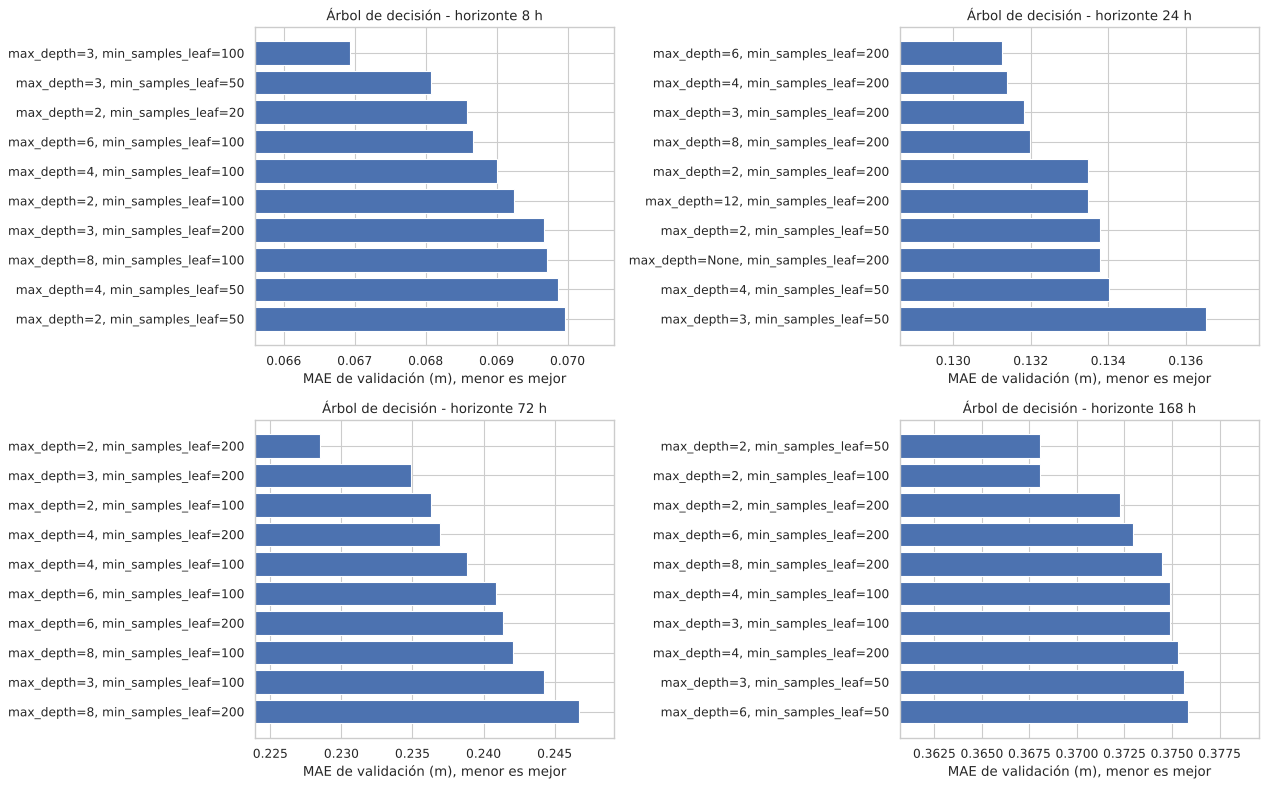

In [ ]:
parametros_arbol = {
    "max_depth": [2, 3, 4, 6, 8, 12, None],
    "min_samples_leaf": [5, 20, 50, 100, 200],
}
mejor_arbol, busqueda_arbol = buscar_hiperparametros(
    "arbol_ajustado",
    DecisionTreeRegressor(random_state=42),
    parametros_arbol,
)
mostrar_top(busqueda_arbol)
display(mejor_arbol.round(4))
comparar_con_lineas_base("arbol_inicial", "arbol_ajustado")
graficar_top(busqueda_arbol, "Árbol de decisión")

> ✏️ **Para redactar** (borrar esta nota y escribir el análisis con sus palabras):
>
> - Mejores: 8 h → profundidad 3, hoja 100; 24 h → 6, 200; 72 h → 2, 200; 168 h → 2, 50.
> - **Prefiere árboles muy simples**, sobre todo en horizontes largos (profundidad 2). Varios quedaron en el borde (profundidad 2 o hoja 200): con datos tan ruidosos, un árbol más complejo se aprende detalles que no se repiten en otros periodos.
> - MAE en prueba: 0,128 (8 h), **0,189 (24 h, el mejor de todos los modelos en ese horizonte)**, 0,263 (72 h), 0,323 (168 h).
> - Frente al inicial mejoró a 8, 24 y 168 h, pero empeoró a 72 h (0,263 frente a 0,227): lo que fue mejor en validación no fue lo mejor en la prueba.

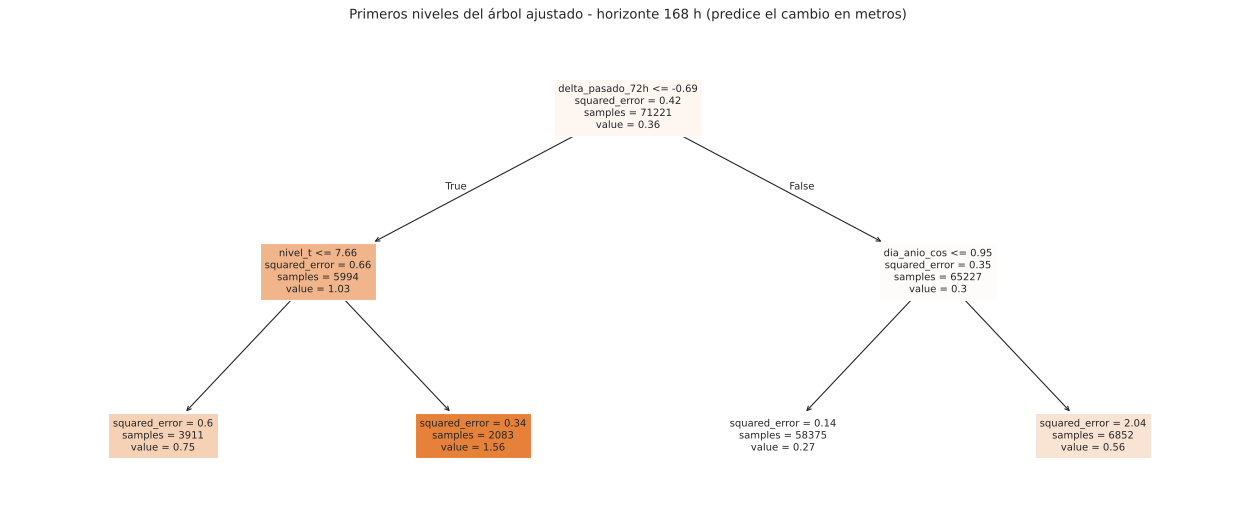

In [ ]:
arbol_168 = modelos_entrenados["arbol_ajustado"][168]
plt.figure(figsize=(20, 8))
plot_tree(arbol_168, max_depth=2, feature_names=columnas_predictores, filled=True, fontsize=9, precision=2)
plt.title("Primeros niveles del árbol ajustado - horizonte 168 h (predice el cambio en metros)")
plt.show()

> ✏️ **Para redactar** (borrar esta nota y escribir el análisis con sus palabras):
>
> - Primeros niveles del árbol de 168 h. La primera pregunta es si `delta_pasado_72h` ≤ −0,69, es decir, si el río está más de 0,69 m por debajo de su máximo de los últimos 3 días.
> - Si es así, el árbol predice que en la próxima semana el máximo estará ~1 m por encima del nivel actual (y 1,56 m si además el nivel es mayor a 7,66 m).
> - En el otro lado pregunta por `dia_anio_cos` (la época del año). Las hojas muestran cuántas filas caen en cada una y el cambio promedio que predicen.

## 10. Random Forest

### 10.1 Modelo inicial de Random Forest

> ✏️ **Para redactar** (borrar esta nota y escribir el análisis con sus palabras):
>
> - Random Forest entrena muchos árboles, cada uno con una muestra al azar de las filas y de las variables, y promedia sus predicciones. Así se reduce el sobreajuste de un solo árbol.
> - Configuración inicial: 100 árboles, `max_depth = 16`, `min_samples_leaf = 5`.

In [ ]:
tabla_rf_inicial = entrenar_modelo_inicial(
    "random_forest_inicial",
    lambda: RandomForestRegressor(
        n_estimators=100, max_depth=16, min_samples_leaf=5, random_state=42, n_jobs=-1
    ),
)
display(tabla_rf_inicial.round(4))
comparar_con_lineas_base("random_forest_inicial")

,modelo,horizonte_horas,muestras_prueba,MAE_m,RMSE_m,R2,MAPE_%
0,random_forest_inicial,8,17845,0.1362,0.2797,0.9518,1.6903
1,random_forest_inicial,24,17876,0.2098,0.3549,0.9346,2.6832
2,random_forest_inicial,72,17885,0.3173,0.4444,0.9100,4.2464
3,random_forest_inicial,168,17888,0.4287,0.5637,0.8631,6.1854


,horizonte_horas,mejor_linea_base,MAE_linea_base_m,MAE_random_forest_inicial_m,mejora_random_forest_inicial_%
0,8,persistencia_pura,0.1144,0.1362,-18.9954
1,24,persistencia_maximo_pasado,0.2187,0.2098,4.0482
2,72,persistencia_maximo_pasado,0.2693,0.3173,-17.8176
3,168,persistencia_maximo_pasado,0.3895,0.4287,-10.0661


> ✏️ **Para redactar** (borrar esta nota y escribir el análisis con sus palabras):
>
> - MAE: 0,136 (8 h), 0,210 (24 h), 0,317 (72 h), 0,429 (168 h).
> - Solo supera a la línea base a 24 h (+4,0 %); a 72 h (−17,8 %) y 168 h (−10,1 %) es **peor que la regla simple**.
> - Con árboles tan profundos (16 niveles) y hojas tan pequeñas (5 filas), el bosque se sobreajusta. Por eso hace falta ajustar.

### 10.2 Búsqueda de hiperparámetros de Random Forest con GridSearchCV

> ✏️ **Para redactar** (borrar esta nota y escribir el análisis con sus palabras):
>
> - Se prueban **36 combinaciones**: `max_depth` [4, 6, 8, 12] × `min_samples_leaf` [10, 30, 60] × `max_features` [sqrt, 0,6, 1,0] (cuántas variables puede mirar cada división).
> - `n_estimators` se deja fijo en 100, porque en una búsqueda anterior 60 y 120 árboles daban casi lo mismo.
> - **Secuencia de decisiones:** una primera búsqueda más amplia (profundidad hasta sin límite, hojas de 2 a 30) escogió profundidad 6 en los 4 horizontes (el mínimo que probó) y hoja 30 en 3 de 4 (el máximo). Por eso esta grilla se centra alrededor de esos valores.

,horizonte_horas,configuracion,MAE_CV_m
2,8,"max_depth=4, max_features=sqrt, min_samples_leaf=60",0.0667
20,8,"max_depth=8, max_features=sqrt, min_samples_leaf=60",0.0672
5,8,"max_depth=4, max_features=0.6, min_samples_leaf=60",0.0675
14,8,"max_depth=6, max_features=0.6, min_samples_leaf=60",0.0676
11,8,"max_depth=6, max_features=sqrt, min_samples_leaf=60",0.0676
43,24,"max_depth=4, max_features=1.0, min_samples_leaf=30",0.1287
38,24,"max_depth=4, max_features=sqrt, min_samples_leaf=60",0.1293
47,24,"max_depth=6, max_features=sqrt, min_samples_leaf=60",0.1294
41,24,"max_depth=4, max_features=0.6, min_samples_leaf=60",0.1295
52,24,"max_depth=6, max_features=1.0, min_samples_leaf=30",0.1296


,modelo,horizonte_horas,mejor_configuracion,MAE_CV_m,muestras_prueba,MAE_m,RMSE_m,R2,MAPE_%
0,random_forest_ajustado,8,"max_depth=4, max_features=sqrt, min_samples_leaf=60",0.0667,17845,0.1252,0.2635,0.9572,1.5468
1,random_forest_ajustado,24,"max_depth=4, max_features=1.0, min_samples_leaf=30",0.1287,17876,0.1926,0.3202,0.9467,2.4301
2,random_forest_ajustado,72,"max_depth=6, max_features=sqrt, min_samples_leaf=60",0.2238,17885,0.2123,0.3117,0.9557,2.8590
3,random_forest_ajustado,168,"max_depth=8, max_features=sqrt, min_samples_leaf=60",0.3532,17888,0.2774,0.3616,0.9437,3.8745


,horizonte_horas,mejor_linea_base,MAE_linea_base_m,MAE_random_forest_inicial_m,mejora_random_forest_inicial_%,MAE_random_forest_ajustado_m,mejora_random_forest_ajustado_%
0,8,persistencia_pura,0.1144,0.1362,-18.9954,0.1252,-9.3749
1,24,persistencia_maximo_pasado,0.2187,0.2098,4.0482,0.1926,11.9521
2,72,persistencia_maximo_pasado,0.2693,0.3173,-17.8176,0.2123,21.1945
3,168,persistencia_maximo_pasado,0.3895,0.4287,-10.0661,0.2774,28.7776


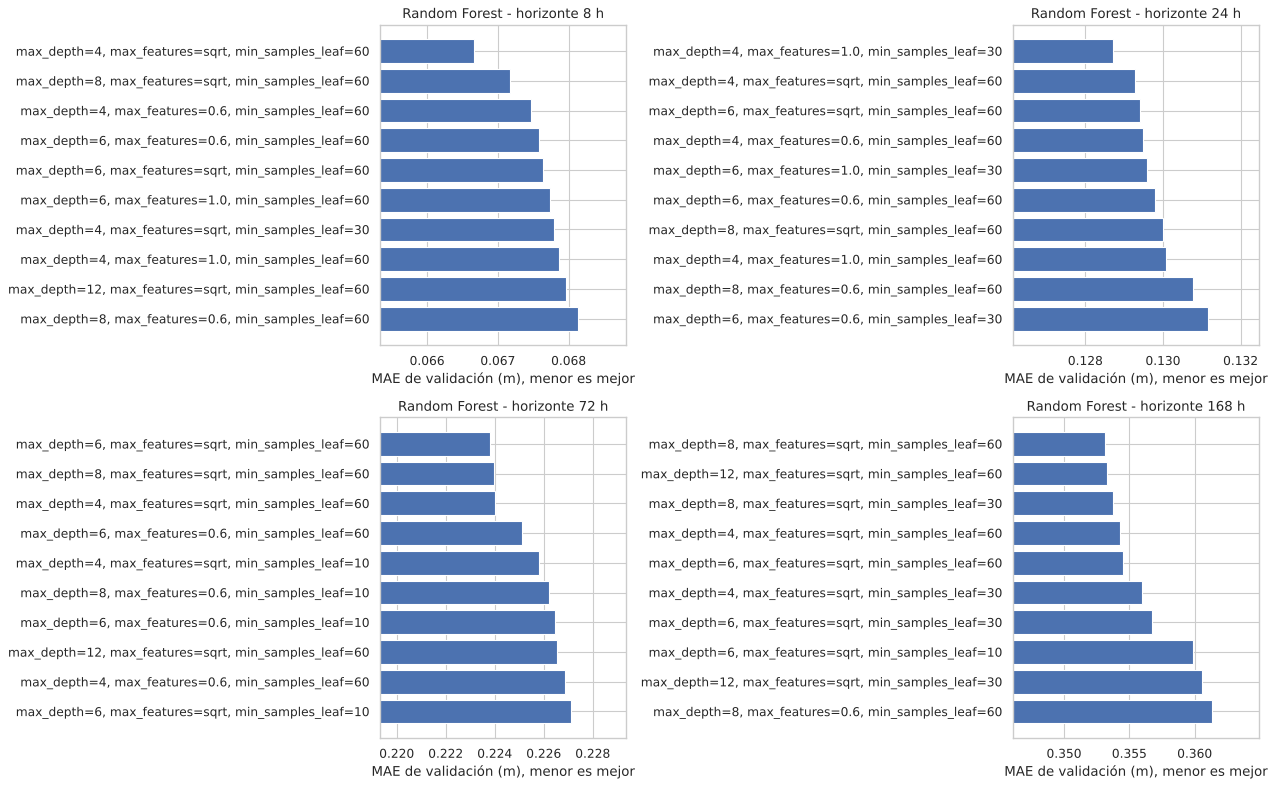

In [ ]:
parametros_rf = {
    "max_depth": [4, 6, 8, 12],
    "min_samples_leaf": [10, 30, 60],
    "max_features": ["sqrt", 0.6, 1.0],
}
mejor_rf, busqueda_rf = buscar_hiperparametros(
    "random_forest_ajustado",
    RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=1),
    parametros_rf,
)
mostrar_top(busqueda_rf)
display(mejor_rf.round(4))
comparar_con_lineas_base("random_forest_inicial", "random_forest_ajustado")
graficar_top(busqueda_rf, "Random Forest")

> ✏️ **Para redactar** (borrar esta nota y escribir el análisis con sus palabras):
>
> - Mejores: 8 h → profundidad 4, sqrt, hoja 60; 24 h → 4, 1,0, hoja 30; 72 h → 6, sqrt, hoja 60; 168 h → 8, sqrt, hoja 60.
> - **El ajuste mejoró muchísimo** frente al inicial: a 168 h el MAE bajó de 0,429 a **0,277** (35 % menos error) y a 72 h de 0,317 a 0,212.
> - Frente a la línea base: **+12,0 % (24 h), +21,2 % (72 h), +28,8 % (168 h)**. A 8 h sigue sin ganarle (−9,4 %).
> - **Es el mejor modelo a 168 h** y el más estable de 24 a 168 h.
> - Otra vez gana la hoja más grande (60, el borde de la grilla) y profundidades bajas: los modelos más simples generalizan mejor.
> - A 72 y 168 h el error de prueba es **menor** que el de validación (168 h: 0,277 frente a 0,353). Es normal: la prueba (2025-2026) no tuvo crecientes tan extremas como 2022, y la validación sí incluye periodos difíciles (como el de la falla del sensor).

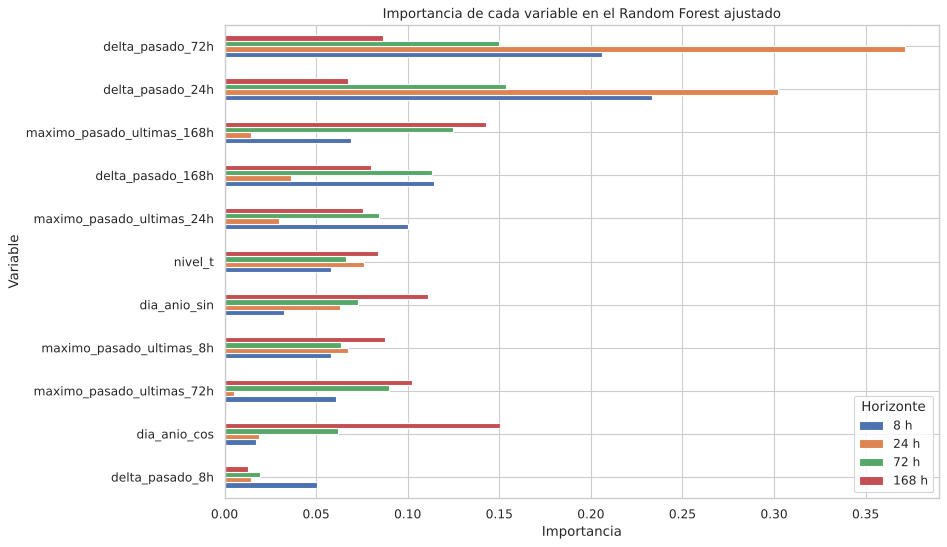

In [ ]:
importancias = pd.DataFrame({
    f"{horizonte} h": pd.Series(modelo.feature_importances_, index=columnas_predictores)
    for horizonte, modelo in modelos_entrenados["random_forest_ajustado"].items()
})
importancias = importancias.loc[importancias.mean(axis=1).sort_values().index]

importancias.plot.barh(figsize=(12, 7))
plt.title("Importancia de cada variable en el Random Forest ajustado")
plt.xlabel("Importancia")
plt.ylabel("Variable")
plt.legend(title="Horizonte")
plt.tight_layout()
plt.show()

> ✏️ **Para redactar** (borrar esta nota y escribir el análisis con sus palabras):
>
> - Las variables más importantes son `delta_pasado_72h` y `delta_pasado_24h`: el modelo se fija sobre todo en **si el río viene subiendo o bajando**.
> - A 168 h ganan peso `maximo_pasado_ultimas_168h` y la época del año (`dia_anio_cos` y `dia_anio_sin`): a largo plazo importa en qué temporada estamos.
> - `delta_pasado_8h` es la menos importante.

## 11. Perceptrón multicapa (MLP)

### 11.1 Modelo inicial de MLP


> - Un MLP (perceptrón multicapa) es una red neuronal que esta organizada en capas. Cada neurona recibe las variabless predictoras, las multiplica por unos pesos, las suma y aplica una función de activación; en el entrenamiento la red ajusta esos pesos para equivocarse lo menos posible.
> - Configuración inicial: 1 capa oculta de 50 neuronas, activación `relu`, hasta 300 vueltas (`max_iter`) y `early_stopping`, que detiene el entrenamiento cuando deja de mejorar.
> - Va con `StandardScaler` en un `Pipeline`, porque las redes aprenden mal si las variables tienen escalas muy distintas.

In [ ]:
tabla_mlp_inicial = entrenar_modelo_inicial(
    "mlp_inicial",
    lambda: Pipeline([
        ("escalador", StandardScaler()),
        ("mlp", MLPRegressor(
            hidden_layer_sizes=(50,), activation="relu",
            max_iter=300, early_stopping=True, random_state=42,
        )),
    ]),
)
display(tabla_mlp_inicial.round(4))
comparar_con_lineas_base("mlp_inicial")

,modelo,horizonte_horas,muestras_prueba,MAE_m,RMSE_m,R2,MAPE_%
0,mlp_inicial,8,17845,0.1456,0.2729,0.9541,1.8564
1,mlp_inicial,24,17876,0.2063,0.3175,0.9476,2.6883
2,mlp_inicial,72,17885,0.2569,0.3619,0.9403,3.5277
3,mlp_inicial,168,17888,0.3456,0.4584,0.9095,4.7624


,horizonte_horas,mejor_linea_base,MAE_linea_base_m,MAE_mlp_inicial_m,mejora_mlp_inicial_%
0,8,persistencia_pura,0.1144,0.1456,-27.2252
1,24,persistencia_maximo_pasado,0.2187,0.2063,5.6915
2,72,persistencia_maximo_pasado,0.2693,0.2569,4.6239
3,168,persistencia_maximo_pasado,0.3895,0.3456,11.2707



> - MAE: 0,146 (8 h), 0,206 (24 h), 0,257 (72 h), 0,346 (168 h).
> - Supera a la línea base a 24 h (+5,7 %), 72 h (+4,6 %) y 168 h (+11,3 %); a 8 h es el peor de los iniciales (−27,2 %).

> - Esto lo que indica es que las predicciones se vuelven menos precisas cuando intentamos anticipar el comportamiento del rio a periodos mas largos.

### 11.2 Búsqueda de hiperparámetros del MLP con GridSearchCV


> - Se prueban 16 combinaciones: `hidden_layer_sizes` (1 capa de 16, 32, 64 o 128 neuronas) × `activation` (`relu` o `tanh`) × `alpha` (0,0001 o 0,01; regularización, igual idea que en Ridge).

,horizonte_horas,configuracion,MAE_CV_m
14,8,"activation=tanh, alpha=0.01, hidden_layer_sizes=(64,)",0.0919
10,8,"activation=tanh, alpha=0.0001, hidden_layer_sizes=(64,)",0.0923
7,8,"activation=relu, alpha=0.01, hidden_layer_sizes=(128,)",0.0933
3,8,"activation=relu, alpha=0.0001, hidden_layer_sizes=(128,)",0.0952
6,8,"activation=relu, alpha=0.01, hidden_layer_sizes=(64,)",0.0985
18,24,"activation=relu, alpha=0.0001, hidden_layer_sizes=(64,)",0.1702
19,24,"activation=relu, alpha=0.0001, hidden_layer_sizes=(128,)",0.1717
16,24,"activation=relu, alpha=0.0001, hidden_layer_sizes=(16,)",0.1723
31,24,"activation=tanh, alpha=0.01, hidden_layer_sizes=(128,)",0.1724
23,24,"activation=relu, alpha=0.01, hidden_layer_sizes=(128,)",0.1730


,modelo,horizonte_horas,mejor_configuracion,MAE_CV_m,muestras_prueba,MAE_m,RMSE_m,R2,MAPE_%
0,mlp_ajustado,8,"activation=tanh, alpha=0.01, hidden_layer_sizes=(64,)",0.0919,17845,0.1366,0.2733,0.9540,1.7143
1,mlp_ajustado,24,"activation=relu, alpha=0.0001, hidden_layer_sizes=(64,)",0.1702,17876,0.2220,0.3283,0.9440,2.9787
2,mlp_ajustado,72,"activation=relu, alpha=0.0001, hidden_layer_sizes=(16,)",0.2968,17885,0.2071,0.3080,0.9568,2.8060
3,mlp_ajustado,168,"activation=relu, alpha=0.0001, hidden_layer_sizes=(32,)",0.5328,17888,0.3239,0.4272,0.9214,4.4987


,horizonte_horas,mejor_linea_base,MAE_linea_base_m,MAE_mlp_inicial_m,mejora_mlp_inicial_%,MAE_mlp_ajustado_m,mejora_mlp_ajustado_%
0,8,persistencia_pura,0.1144,0.1456,-27.2252,0.1366,-19.3757
1,24,persistencia_maximo_pasado,0.2187,0.2063,5.6915,0.2220,-1.5041
2,72,persistencia_maximo_pasado,0.2693,0.2569,4.6239,0.2071,23.1250
3,168,persistencia_maximo_pasado,0.3895,0.3456,11.2707,0.3239,16.8396


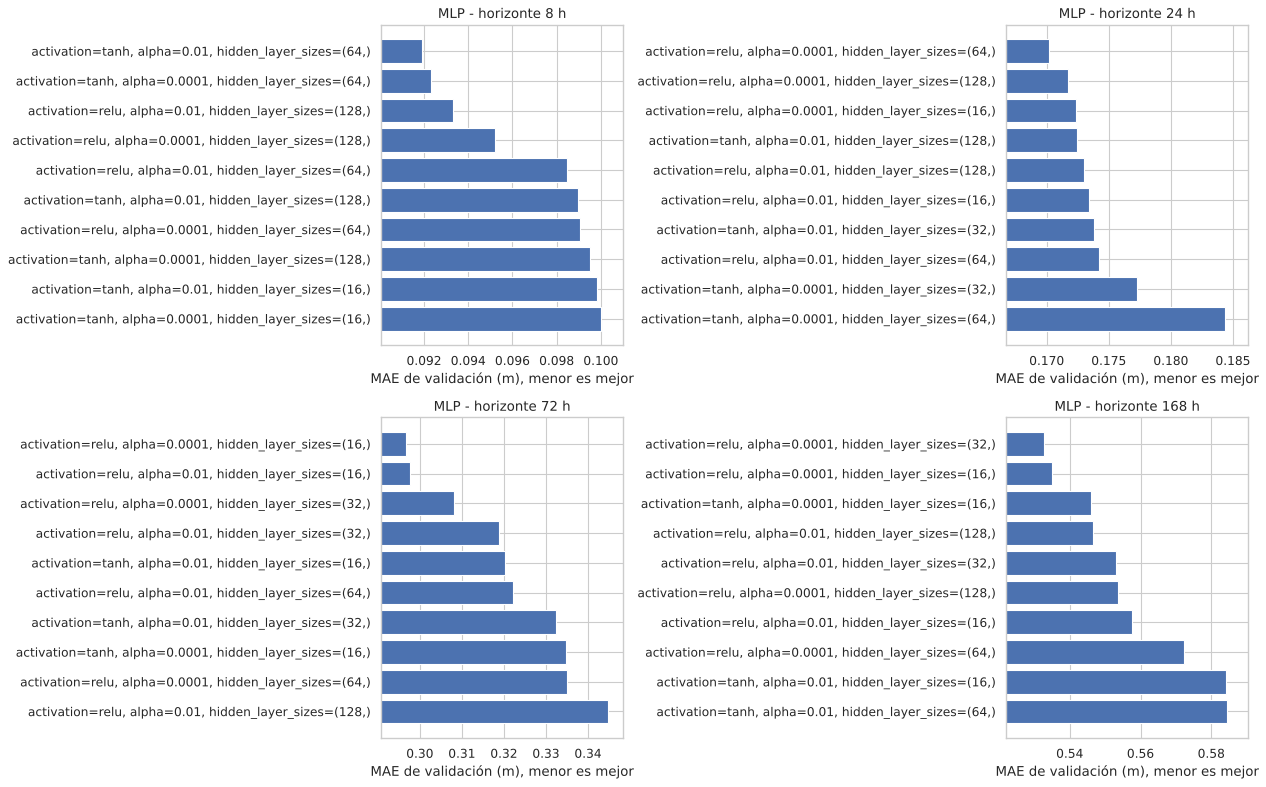

In [ ]:
parametros_mlp = {
    "mlp__hidden_layer_sizes": [(16,), (32,), (64,), (128,)],
    "mlp__activation": ["relu", "tanh"],
    "mlp__alpha": [0.0001, 0.01],
}
mejor_mlp, busqueda_mlp = buscar_hiperparametros(
    "mlp_ajustado",
    Pipeline([
        ("escalador", StandardScaler()),
        ("mlp", MLPRegressor(max_iter=300, early_stopping=True, random_state=42)),
    ]),
    parametros_mlp,
)
mostrar_top(busqueda_mlp)
display(mejor_mlp.round(4))
comparar_con_lineas_base("mlp_inicial", "mlp_ajustado")
graficar_top(busqueda_mlp, "MLP")


>
> - Mejores: 8 h → 64 neuronas, `tanh`, alpha 0,01; 24 h → 64, `relu`; 72 h → 16, `relu`; 168 h → 32, `relu`. `relu` ganó en 3 de los 4 horizontes.
> - **A 72 h es el mejor de todos los modelos: MAE 0,207 (+23,1 % frente a la línea base)**. A 168 h mejora un 16,8 %.
> - A 8 h (−19,4 %) y 24 h (−1,5 %) no le gana a la línea base.
> - El error de validación de las redes es mucho más alto y variable que el de los árboles (168 h: 0,533 frente a 0,353 del Random Forest). Las redes son sensibles a los valores extremos de los deltas (−11 a +7 m) que quedaron del periodo de falla del sensor, y esos periodos caen en los pliegues de validación.
> - Algunas combinaciones llegaron al máximo de 300 iteraciones sin terminar de converger (aviso `ConvergenceWarning` al ejecutar).
> - Esto lo que demuestra es que no existe una configuracion ideal para todos los escenarios sino que el comportamiento del modelo depende del tiempo que queremos anticipar.

## 12. Red neuronal profunda (DNN)

### 12.1 Modelo inicial de DNN


>
> - Una DNN (red profunda) es un MLP con **varias capas ocultas**. Más capas le permiten aprender relaciones más complejas, pero se sobreajusta más fácil y tarda más.
> - Configuración inicial: 3 capas ocultas de 64, 32 y 16 neuronas, `relu` y `early_stopping`.

In [ ]:
tabla_dnn_inicial = entrenar_modelo_inicial(
    "dnn_inicial",
    lambda: Pipeline([
        ("escalador", StandardScaler()),
        ("dnn", MLPRegressor(
            hidden_layer_sizes=(64, 32, 16), activation="relu",
            max_iter=300, early_stopping=True, random_state=42,
        )),
    ]),
)
display(tabla_dnn_inicial.round(4))
comparar_con_lineas_base("dnn_inicial")

,modelo,horizonte_horas,muestras_prueba,MAE_m,RMSE_m,R2,MAPE_%
0,dnn_inicial,8,17845,0.1678,0.3608,0.9198,2.0649
1,dnn_inicial,24,17876,0.3582,0.6359,0.7900,4.4831
2,dnn_inicial,72,17885,0.3810,0.5271,0.8734,5.2937
3,dnn_inicial,168,17888,0.4450,0.6095,0.8400,6.3961


,horizonte_horas,mejor_linea_base,MAE_linea_base_m,MAE_dnn_inicial_m,mejora_dnn_inicial_%
0,8,persistencia_pura,0.1144,0.1678,-46.6466
1,24,persistencia_maximo_pasado,0.2187,0.3582,-63.7723
2,72,persistencia_maximo_pasado,0.2693,0.3810,-41.4452
3,168,persistencia_maximo_pasado,0.3895,0.4450,-14.2533


> ✏️ **Para redactar** (borrar esta nota y escribir el análisis con sus palabras):
>
> - MAE: 0,168 (8 h), 0,358 (24 h), 0,381 (72 h), 0,445 (168 h).
> - **Es peor que la línea base en los 4 horizontes** (de −14 % a −64 %). Es el peor modelo inicial.

### 12.2 Búsqueda de hiperparámetros de la DNN con GridSearchCV


> - Se prueban **15 combinaciones**: 5 arquitecturas (de 2 a 4 capas, hasta (256, 128, 64, 32)) × 3 valores de alpha. Solo `relu`, porque ganó en 3 de 4 horizontes del MLP.
> - Se incluyó la red (256, 128, 64, 32) porque en una prueba anterior la red más grande quedó en el borde de la grilla.

,horizonte_horas,configuracion,MAE_CV_m
12,8,"alpha=0.01, hidden_layer_sizes=(128, 64, 32)",0.0882
14,8,"alpha=0.01, hidden_layer_sizes=(256, 128, 64, 32)",0.0892
9,8,"alpha=0.001, hidden_layer_sizes=(256, 128, 64, 32)",0.0925
13,8,"alpha=0.01, hidden_layer_sizes=(128, 64, 32, 16)",0.0929
2,8,"alpha=0.0001, hidden_layer_sizes=(128, 64, 32)",0.0950
19,24,"alpha=0.0001, hidden_layer_sizes=(256, 128, 64, 32)",0.1750
23,24,"alpha=0.001, hidden_layer_sizes=(128, 64, 32, 16)",0.1765
24,24,"alpha=0.001, hidden_layer_sizes=(256, 128, 64, 32)",0.1807
29,24,"alpha=0.01, hidden_layer_sizes=(256, 128, 64, 32)",0.1813
27,24,"alpha=0.01, hidden_layer_sizes=(128, 64, 32)",0.1827


,modelo,horizonte_horas,mejor_configuracion,MAE_CV_m,muestras_prueba,MAE_m,RMSE_m,R2,MAPE_%
0,dnn_ajustado,8,"alpha=0.01, hidden_layer_sizes=(128, 64, 32)",0.0882,17845,0.1497,0.2895,0.9484,1.9415
1,dnn_ajustado,24,"alpha=0.0001, hidden_layer_sizes=(256, 128, 64, 32)",0.1750,17876,0.2820,0.4873,0.8766,3.7126
2,dnn_ajustado,72,"alpha=0.01, hidden_layer_sizes=(256, 128, 64, 32)",0.3088,17885,0.3182,0.4689,0.8998,4.4608
3,dnn_ajustado,168,"alpha=0.01, hidden_layer_sizes=(128, 64, 32)",0.4934,17888,0.4325,0.5822,0.8540,6.0187


,horizonte_horas,mejor_linea_base,MAE_linea_base_m,MAE_dnn_inicial_m,mejora_dnn_inicial_%,MAE_dnn_ajustado_m,mejora_dnn_ajustado_%
0,8,persistencia_pura,0.1144,0.1678,-46.6466,0.1497,-30.8331
1,24,persistencia_maximo_pasado,0.2187,0.3582,-63.7723,0.2820,-28.9559
2,72,persistencia_maximo_pasado,0.2693,0.3810,-41.4452,0.3182,-18.1384
3,168,persistencia_maximo_pasado,0.3895,0.4450,-14.2533,0.4325,-11.0486


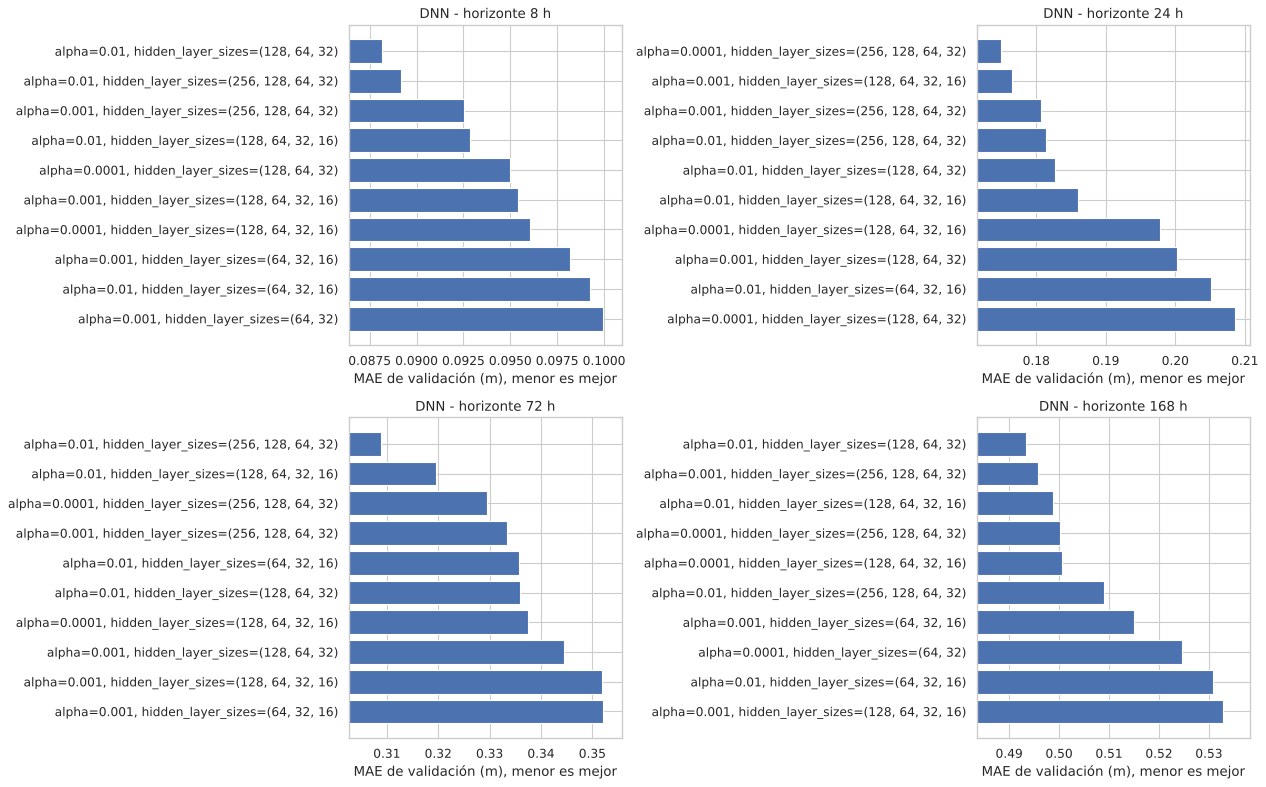

In [ ]:
parametros_dnn = {
    "dnn__hidden_layer_sizes": [(64, 32), (64, 32, 16), (128, 64, 32), (128, 64, 32, 16), (256, 128, 64, 32)],
    "dnn__alpha": [0.0001, 0.001, 0.01],
}
mejor_dnn, busqueda_dnn = buscar_hiperparametros(
    "dnn_ajustado",
    Pipeline([
        ("escalador", StandardScaler()),
        ("dnn", MLPRegressor(activation="relu", max_iter=300, early_stopping=True, random_state=42)),
    ]),
    parametros_dnn,
)
mostrar_top(busqueda_dnn)
display(mejor_dnn.round(4))
comparar_con_lineas_base("dnn_inicial", "dnn_ajustado")
graficar_top(busqueda_dnn, "DNN")


> - Mejores: 8 h → (128, 64, 32), alpha 0,01; 24 h → (256, 128, 64, 32); 72 h → (256, 128, 64, 32); 168 h → (128, 64, 32).
> - Mejoró frente a la inicial, pero sigue siendo peor que la línea base en los 4 horizontes (−11 % a −31 %).
> - Más capas no ayudaron: con 11 predictores, el MLP de una capa fue mucho mejor. La DNN es la más afectada por los valores extremos del periodo de falla del sensor.
> - A 24 y 72 h volvió a ganar la red más grande (borde de la grilla); se deja como limitación por tiempo de cómputo.

## 13. Comparación entre los modelos


>
> - Se reúnen las métricas de prueba de las 2 líneas base y los 10 modelos (5 métodos × inicial/ajustado). Todos se evaluaron sobre las mismas filas de prueba.

In [ ]:
tabla_comparacion = pd.concat(resultados.values(), ignore_index=True)
display(tabla_comparacion.sort_values(["horizonte_horas", "MAE_m"]).reset_index(drop=True).round(4))

,modelo,horizonte_horas,muestras_prueba,MAE_m,RMSE_m,R2,MAPE_%
0,ridge_ajustado,8,17845,0.1144,0.3092,0.9411,1.3760
1,persistencia_pura,8,17845,0.1144,0.3092,0.9411,1.3760
2,random_forest_ajustado,8,17845,0.1252,0.2635,0.9572,1.5468
3,ridge_inicial,8,17845,0.1269,0.2718,0.9545,1.5783
4,arbol_ajustado,8,17845,0.1277,0.2729,0.9541,1.5833
5,arbol_inicial,8,17845,0.1317,0.2889,0.9486,1.6228
6,random_forest_inicial,8,17845,0.1362,0.2797,0.9518,1.6903
7,mlp_ajustado,8,17845,0.1366,0.2733,0.9540,1.7143
8,mlp_inicial,8,17845,0.1456,0.2729,0.9541,1.8564
9,persistencia_maximo_pasado,8,17845,0.1480,0.3458,0.9263,1.8696


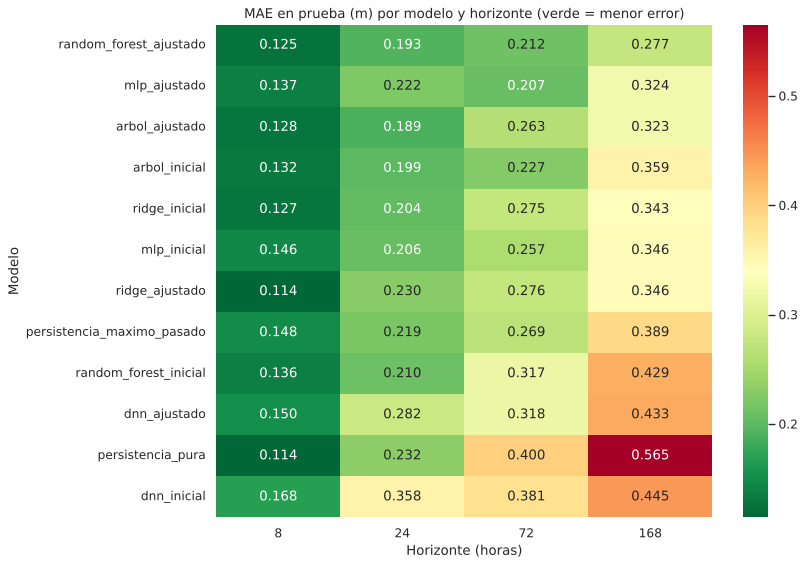

In [ ]:
mae_por_modelo = tabla_comparacion.pivot(index="modelo", columns="horizonte_horas", values="MAE_m")
mae_por_modelo = mae_por_modelo.loc[mae_por_modelo.mean(axis=1).sort_values().index]

plt.figure(figsize=(10, 8))
sns.heatmap(mae_por_modelo, annot=True, fmt=".3f", cmap="RdYlGn_r")
plt.title("MAE en prueba (m) por modelo y horizonte (verde = menor error)")
plt.xlabel("Horizonte (horas)")
plt.ylabel("Modelo")
plt.show()

,horizonte_horas,mejor_linea_base,MAE_linea_base_m,MAE_ridge_ajustado_m,mejora_ridge_ajustado_%,MAE_arbol_ajustado_m,mejora_arbol_ajustado_%,MAE_random_forest_ajustado_m,mejora_random_forest_ajustado_%,MAE_mlp_ajustado_m,mejora_mlp_ajustado_%,MAE_dnn_ajustado_m,mejora_dnn_ajustado_%
0,8,persistencia_pura,0.1144,0.1144,0.0030,0.1277,-11.5811,0.1252,-9.3749,0.1366,-19.3757,0.1497,-30.8331
1,24,persistencia_maximo_pasado,0.2187,0.2302,-5.2420,0.1893,13.4356,0.1926,11.9521,0.2220,-1.5041,0.2820,-28.9559
2,72,persistencia_maximo_pasado,0.2693,0.2759,-2.4468,0.2632,2.2859,0.2123,21.1945,0.2071,23.1250,0.3182,-18.1384
3,168,persistencia_maximo_pasado,0.3895,0.3460,11.1701,0.3230,17.0804,0.2774,28.7776,0.3239,16.8396,0.4325,-11.0486


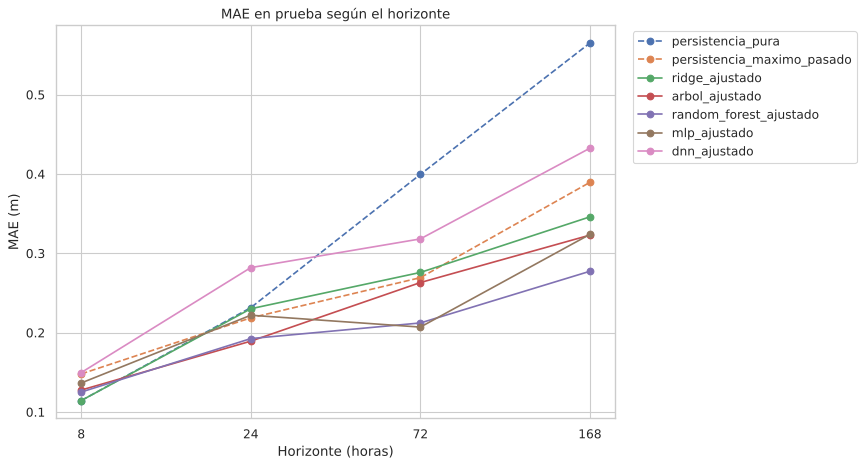

In [ ]:
nombres_ajustados = ["ridge_ajustado", "arbol_ajustado", "random_forest_ajustado", "mlp_ajustado", "dnn_ajustado"]
comparar_con_lineas_base(*nombres_ajustados)

plt.figure(figsize=(11, 6))
for nombre in ["persistencia_pura", "persistencia_maximo_pasado"] + nombres_ajustados:
    tabla = resultados[nombre]
    estilo = "--" if nombre.startswith("persistencia") else "-"
    plt.plot(tabla["horizonte_horas"].astype(str), tabla["MAE_m"], estilo, marker="o", label=nombre)
plt.title("MAE en prueba según el horizonte")
plt.xlabel("Horizonte (horas)")
plt.ylabel("MAE (m)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


>
> - Mejor modelo por horizonte (MAE en prueba):8 h → Ridge ajustado = persistencia pura (0,114); 24 h → árbol ajustado (0,189, +13,4 %); 72 h → MLP ajustado (0,207, +23,1 %), muy cerca del Random Forest (0,212, +21,2 %); 168 h → Random Forest ajustado (0,277, +28,8 %).
> - El Random Forest ajustado es el más estable: está entre los dos mejores de 24 a 168 h y es el único que supera a la línea base por más de 10 % en esos tres horizontes.
> - La ventaja de los modelos crece con el horizonte: a 8 h ninguno supera a la persistencia, y a 168 h el mejor reduce el error casi un 29 %.
> - La DNN fue el peor método en todos los horizontes.
> - En RMSE, varios modelos superan a la persistencia incluso a 8 h (Random Forest ajustado 0,264 frente a 0,309): cometen menos errores grandes, aunque en promedio (MAE) no le ganen.

,modelo,muestras_prueba,MAE_m,RMSE_m,R2,MAPE_%
horizonte_horas,,,,,,
8,ridge_ajustado,17845,0.1144,0.3092,0.9411,1.3760
24,arbol_ajustado,17876,0.1893,0.3392,0.9402,2.3875
72,mlp_ajustado,17885,0.2071,0.3080,0.9568,2.8060
168,random_forest_ajustado,17888,0.2774,0.3616,0.9437,3.8745


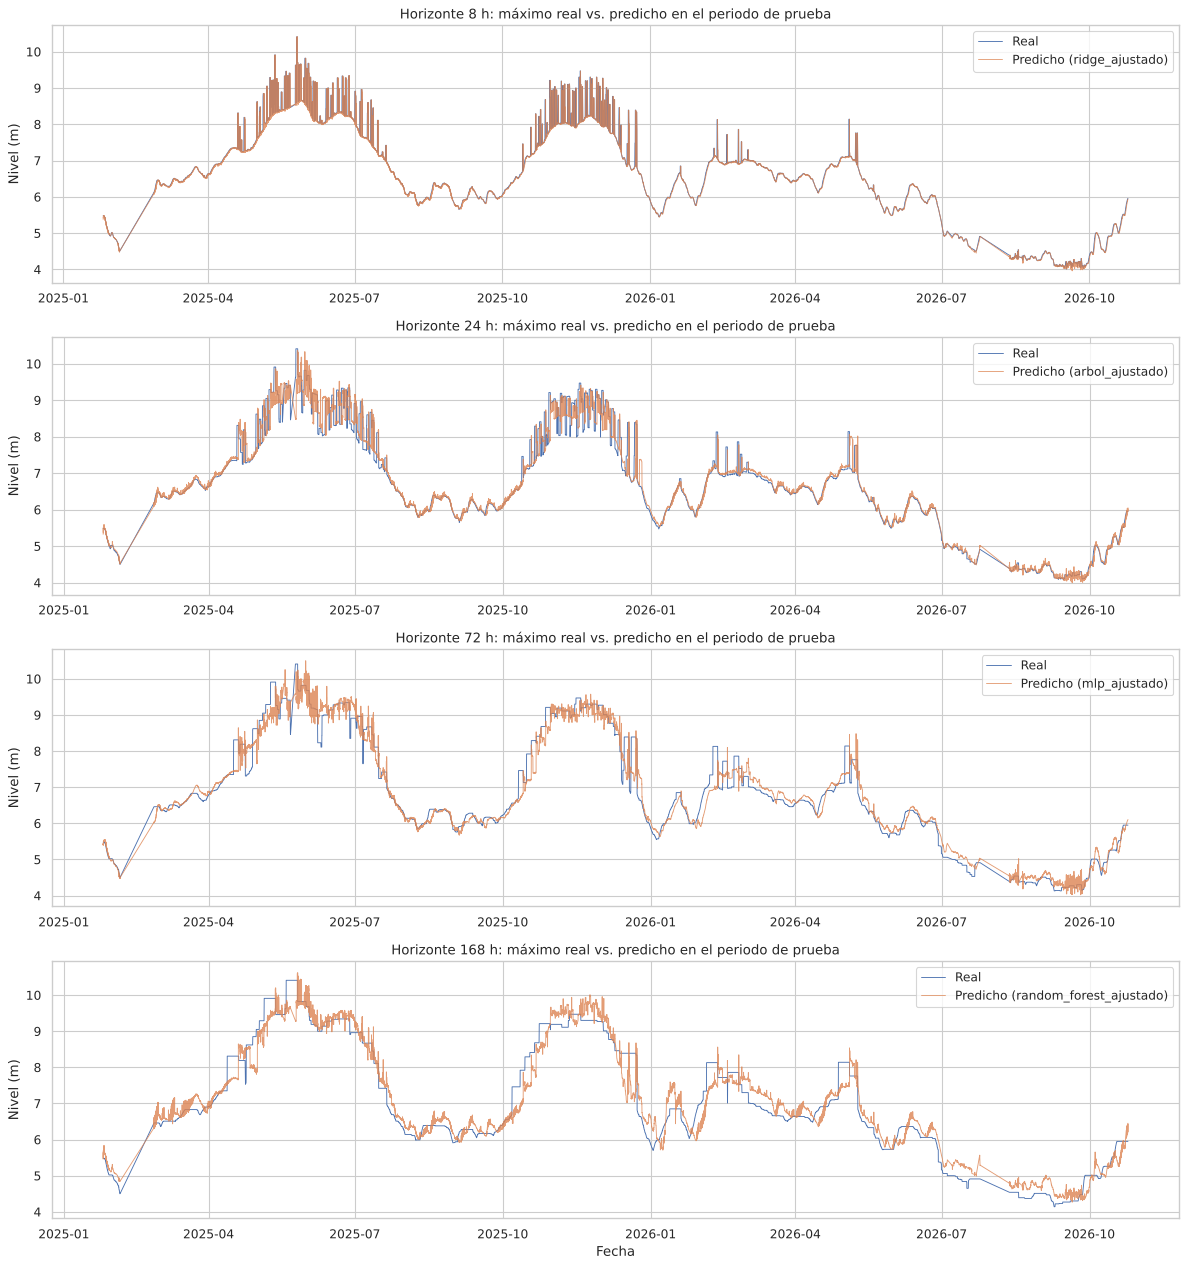

In [ ]:
mejores_por_horizonte = (
    tabla_comparacion[tabla_comparacion["modelo"].isin(modelos_entrenados)]
    .sort_values("MAE_m")
    .groupby("horizonte_horas")
    .head(1)
    .set_index("horizonte_horas")
    .sort_index()
)
display(mejores_por_horizonte.round(4))

fig, ejes = plt.subplots(4, 1, figsize=(15, 16))
for eje, (horizonte, fila) in zip(ejes, mejores_por_horizonte.iterrows()):
    prueba = particiones_por_horizonte[horizonte]["prueba"]
    objetivo = f"maximo_observado_proximas_{horizonte}h"
    modelo = modelos_entrenados[fila["modelo"]][horizonte]
    prediccion = prueba["nivel_t"] + modelo.predict(prueba[columnas_predictores])
    eje.plot(prueba["fecha_origen"], prueba[objetivo], linewidth=0.8, label="Real")
    eje.plot(prueba["fecha_origen"], prediccion, linewidth=0.8, alpha=0.8, label=f"Predicho ({fila['modelo']})")
    eje.set_title(f"Horizonte {horizonte} h: máximo real vs. predicho en el periodo de prueba")
    eje.set_ylabel("Nivel (m)")
    eje.legend(loc="upper right")
ejes[-1].set_xlabel("Fecha")
plt.tight_layout()
plt.show()


>
> - Gráficas del máximo real y el predicho por el mejor modelo de cada horizonte en la prueba (enero 2025 – octubre 2026).
> - Los modelos siguen bien las dos temporadas altas (mayo-julio y octubre-diciembre de 2025) y las bajas.
> - Las líneas verticales sueltas del valor real (sobre todo a 8 y 24 h) son picos aislados del sensor: lecturas que suben 1-2 m y bajan en minutos. Ningún modelo puede predecirlos, y explican buena parte del error.
> - A 168 h el modelo se adelanta o se atrasa unos días en las subidas, pero sigue la forma general del río.

## 14. Conclusiones

> ✏️ **Para redactar** (borrar esta nota y escribir el análisis con sus palabras):
>
> Escriban 4 o 5 párrafos cortos, uno por idea, con sus palabras:
>
> 1. **Respuesta al objetivo:** qué modelo predice mejor el nivel máximo en cada horizonte y por cuánto supera a la regla simple. Datos: 8 h → ninguno supera a la persistencia pura (0,114 m); 24 h → árbol ajustado (0,189 m, 13 % mejor); 72 h → MLP ajustado (0,207 m, 23 % mejor) y Random Forest (0,212 m); 168 h → Random Forest ajustado (0,277 m, 29 % mejor). Recomendación general: **Random Forest ajustado**, por ser el más estable.
> 2. **Por qué funcionó:** el cambio de predictores (máximos de las últimas horas y días, deltas y época del año) fue lo que hizo que los modelos superaran la línea base. Las variables más importantes son las que indican si el río viene subiendo o bajando, y la época del año pesa más a una semana.
> 3. **Corto plazo:** a 8 h el río casi no cambia, y lo mejor es repetir el último nivel. El propio Ridge ajustado llegó a esa misma conclusión (alpha enorme = no predecir cambio).
> 4. **Sobre el ajuste de hiperparámetros:** ayudó mucho en Random Forest (168 h: de 0,429 a 0,277) y en la DNN, poco en Ridge, y en el árbol a 72 h hasta empeoró en prueba. En varios métodos ganaron los modelos más simples (árboles de profundidad 2-4, hojas grandes).
> 5. **Redes neuronales:** el MLP de una capa fue competitivo (el mejor a 72 h), pero la DNN no superó la línea base en ningún horizonte. Más complejidad no significó mejores resultados.
>
> **Limitaciones** (pueden ir en un párrafo aparte): datos crudos no validados por IDEAM; hueco de feb 2021 – ago 2022; una sola estación; quedan lecturas raras del periodo de falla del sensor (dic 2017 – ene 2018, sep 2018) que generan deltas de hasta −11 m; picos sueltos del sensor dentro de los objetivos; varias mejores combinaciones quedaron en el borde de la grilla; la prueba (2025-2026) no tuvo crecientes tan grandes como 2022.

### 14.1 Trabajo futuro

Como trabajo futuro, una de las principales mejoras que se pueden implementar es evaluar el modelo utilizando diferentes periodos de prueba. En lugar de realizar la evaluación únicamente con un periodo específico, se podrían utilizar diferentes intervalos de tiempo para comprobar cómo se comporta el modelo frente a distintas condiciones del río. Esto permitiría determinar si el modelo mantiene su precisión en diferentes temporadas climáticas, especialmente durante épocas de lluvia intensa y sequía.

Otra mejora importante sería incorporar nuevas fuentes de información que actualmente no contempla el modelo. Por ejemplo, agregar datos de precipitación, temperatura, humedad, velocidad del viento, niveles de otros ríos que desembocan en el Magdalena y registros de estaciones hidrológicas cercanas. Estas variables podrían aportar información adicional sobre los factores que influyen en el comportamiento del nivel del río y ayudar a mejorar la capacidad predictiva del modelo, tanto a corto como a largo plazo.

También sería importante continuar experimentando con diferentes algoritmos y técnicas de inteligencia artificial. Se podrían evaluar modelos especializados en series temporales, como LSTM, GRU o modelos híbridos, y compararlos con el MLP desarrollado en este proyecto. Asimismo, se podrían realizar nuevos procesos de optimización de hiperparámetros y selección de variables para identificar qué combinaciones permiten reducir los errores y obtener predicciones más confiables.

### 14.2 Implicaciones éticas

Una de las principales implicaciones éticas de implementar un modelo de inteligencia artificial para predecir el nivel del río Magdalena es la responsabilidad sobre las decisiones que se tomen a partir de sus predicciones. Si el modelo anticipa un aumento del nivel del río, las autoridades podrían utilizar esa información para emitir alertas tempranas, evacuar comunidades o tomar medidas preventivas. Sin embargo, si el modelo presenta errores o predicciones equivocadas, podría generar falsas alarmas o, por el contrario, no advertir a tiempo sobre una posible inundación, poniendo en riesgo la vida de las personas.

Otra implicación importante es la protección de las comunidades que viven cerca del río Magdalena, especialmente aquellas que se encuentran en zonas vulnerables y dependen del comportamiento del río para sus actividades económicas, agrícolas y pesqueras. El uso de esta tecnología debe buscar beneficiar a toda la población y no solamente a los sectores con mayores recursos. Es importante que las alertas y los resultados de las predicciones sean accesibles, comprensibles y lleguen oportunamente a las comunidades que más los necesitan.

También debemos considerar la transparencia y confiabilidad del modelo. Es necesario reconocer que la inteligencia artificial trabaja con datos históricos y patrones de comportamiento, por lo que sus predicciones no son completamente exactas ni pueden garantizar lo que sucederá en el futuro. Factores como las lluvias extremas, los cambios climáticos, las condiciones ambientales y otros fenómenos pueden modificar el comportamiento del río. Por esta razón, las predicciones deben utilizarse como herramientas de apoyo para las autoridades y nunca como sustitutos absolutos del conocimiento de los expertos.